# Comparative Implementation of Machine Learning Regression Algorithms

**Problem:** Predict the **price of a diamond** from its physical and quality characteristics.

**Algorithms compared (same data, same features, same target, same 80:20 split):**

1. Linear Regression
2. Decision Tree Regression
3. Random Forest Regression
4. Neural Network Regression
5. XGBoost Regression
6. K-Nearest Neighbors (KNN) Regression

**Evaluation metrics:** MAE, MSE, RMSE and R² Score.



## 1. Import Libraries and Setup

In [1]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

ASSETS = "assets"
os.makedirs(ASSETS, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "legend.fontsize": 9,
})

MODEL_COLORS = {
    "Linear Regression": "#4C72B0",
    "Decision Tree": "#55A868",
    "Random Forest": "#C44E52",
    "Neural Network": "#8172B3",
    "XGBoost": "#DD8452",
    "KNN": "#937860",
}

def save_fig(fig, name):
    fig.savefig(f"{ASSETS}/{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

## 2. Dataset

**Dataset:** Diamonds dataset (≈ 54,000 diamonds) loaded directly from a public link.

| Feature | Type | Meaning |
|---|---|---|
| carat | numeric | weight of the diamond |
| cut | categorical (ordinal) | quality of cut: Fair < Good < Very Good < Premium < Ideal |
| color | categorical (ordinal) | colour grade: J (worst) to D (best) |
| clarity | categorical (ordinal) | I1 (worst) to IF (best) |
| depth | numeric | total depth percentage = z / mean(x, y) |
| table | numeric | width of top of diamond relative to widest point |
| x, y, z | numeric | length, width, depth in mm |
| **price** | **target** | price in US dollars |

The dataset has **9 input features** and one continuous target, which makes it suitable for a regression comparison.

In [2]:
URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/diamonds.csv"
df = pd.read_csv(URL)
print("Shape:", df.shape)
df.head(10)

Shape: (53940, 10)


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
5,0.24,Very Good,J,VVS2,62.8,57.0,336,3.94,3.96,2.48
6,0.24,Very Good,I,VVS1,62.3,57.0,336,3.95,3.98,2.47
7,0.26,Very Good,H,SI1,61.9,55.0,337,4.07,4.11,2.53
8,0.22,Fair,E,VS2,65.1,61.0,337,3.87,3.78,2.49
9,0.23,Very Good,H,VS1,59.4,61.0,338,4.00,4.05,2.39


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53940 non-null  float64
 1   cut      53940 non-null  object 
 2   color    53940 non-null  object 
 3   clarity  53940 non-null  object 
 4   depth    53940 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  int64  
 7   x        53940 non-null  float64
 8   y        53940 non-null  float64
 9   z        53940 non-null  float64
dtypes: float64(6), int64(1), object(3)
memory usage: 4.1+ MB


In [4]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
carat,53940.0,0.798,0.474,0.2,0.40,0.70,1.04,5.01
depth,53940.0,61.749,1.433,43.0,61.00,61.80,62.50,79.00
table,53940.0,57.457,2.234,43.0,56.00,57.00,59.00,95.00
price,53940.0,3932.800,3989.440,326.0,950.00,2401.00,5324.25,18823.00
x,53940.0,5.731,1.122,0.0,4.71,5.70,6.54,10.74
y,53940.0,5.735,1.142,0.0,4.72,5.71,6.54,58.90
z,53940.0,3.539,0.706,0.0,2.91,3.53,4.04,31.80


In [5]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Rows with a zero dimension (x, y or z = 0):", ((df[["x", "y", "z"]] == 0).any(axis=1)).sum())

Missing values per column:
carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64

Duplicate rows: 146
Rows with a zero dimension (x, y or z = 0): 20


## 3. Exploratory Data Analysis

### 3.1 Distribution of the Target Variable (Price)

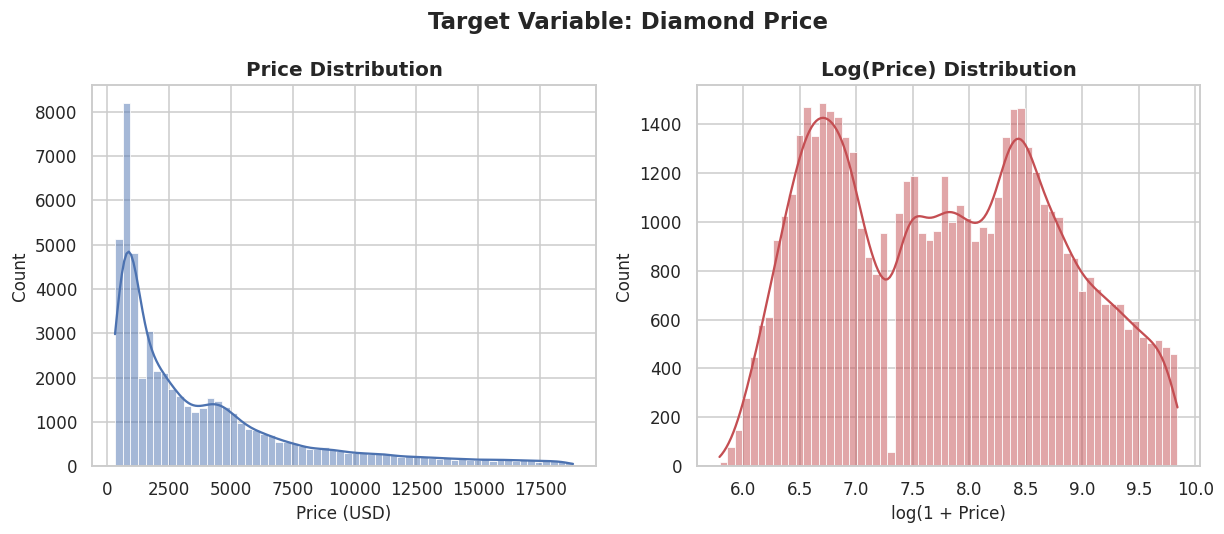

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df["price"], bins=60, kde=True, color="#4C72B0", ax=axes[0])
axes[0].set_title("Price Distribution")
axes[0].set_xlabel("Price (USD)")
sns.histplot(np.log1p(df["price"]), bins=60, kde=True, color="#C44E52", ax=axes[1])
axes[1].set_title("Log(Price) Distribution")
axes[1].set_xlabel("log(1 + Price)")
fig.suptitle("Target Variable: Diamond Price", fontsize=15, fontweight="bold", y=1.03)
save_fig(fig, "01_price_distribution")

### 3.2 Distribution of Numeric Features

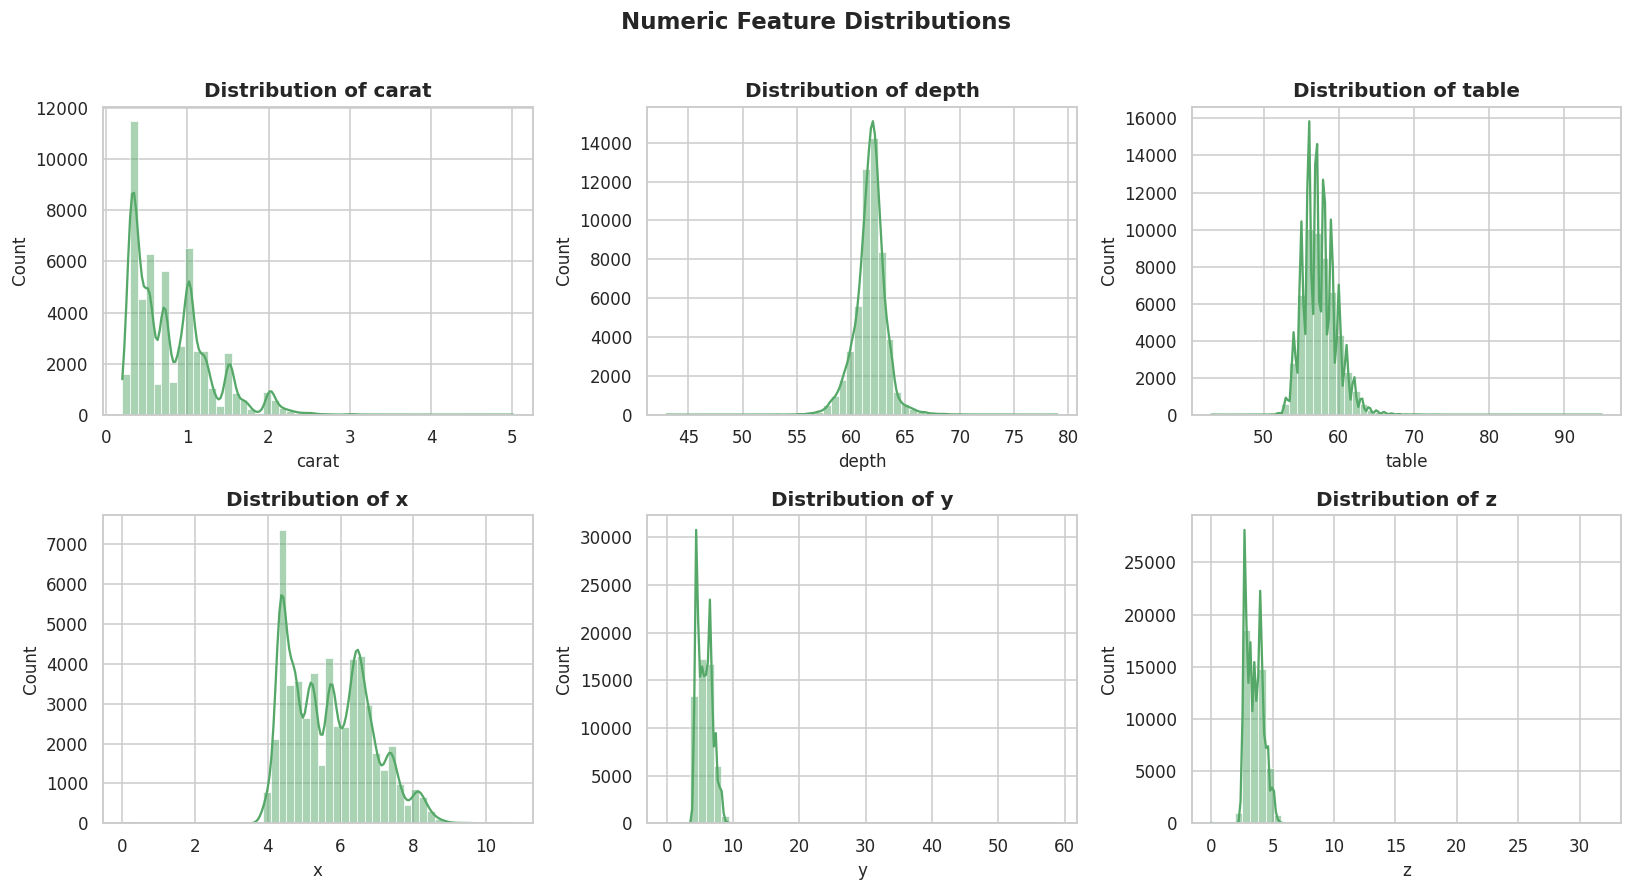

In [7]:
num_cols = ["carat", "depth", "table", "x", "y", "z"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col], bins=50, kde=True, color="#55A868", ax=ax)
    ax.set_title(f"Distribution of {col}")
fig.suptitle("Numeric Feature Distributions", fontsize=15, fontweight="bold", y=1.01)
fig.tight_layout()
save_fig(fig, "02_numeric_feature_distributions")

### 3.3 Categorical Features

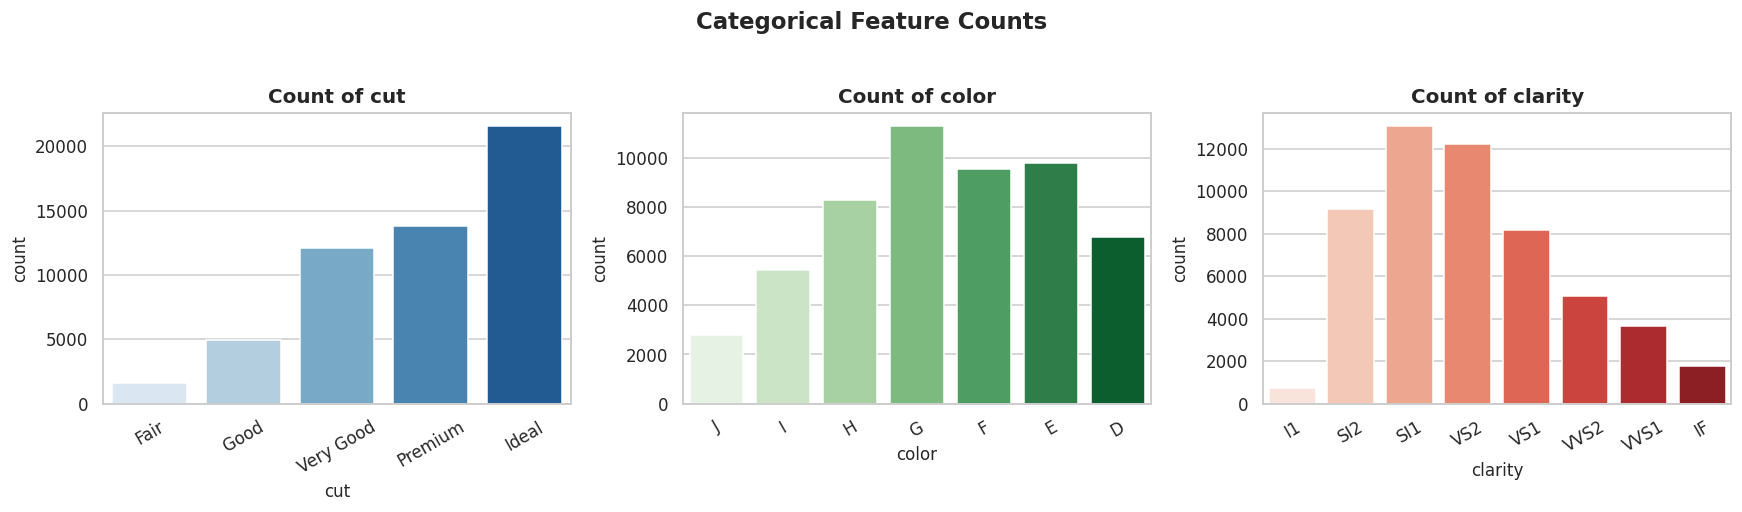

In [8]:
cut_order = ["Fair", "Good", "Very Good", "Premium", "Ideal"]
color_order = ["J", "I", "H", "G", "F", "E", "D"]
clarity_order = ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col, order, pal in zip(axes, ["cut", "color", "clarity"],
                               [cut_order, color_order, clarity_order],
                               ["Blues", "Greens", "Reds"]):
    sns.countplot(data=df, x=col, order=order, palette=pal, ax=ax)
    ax.set_title(f"Count of {col}")
    ax.tick_params(axis="x", rotation=30)
fig.suptitle("Categorical Feature Counts", fontsize=15, fontweight="bold", y=1.03)
fig.tight_layout()
save_fig(fig, "03_categorical_counts")

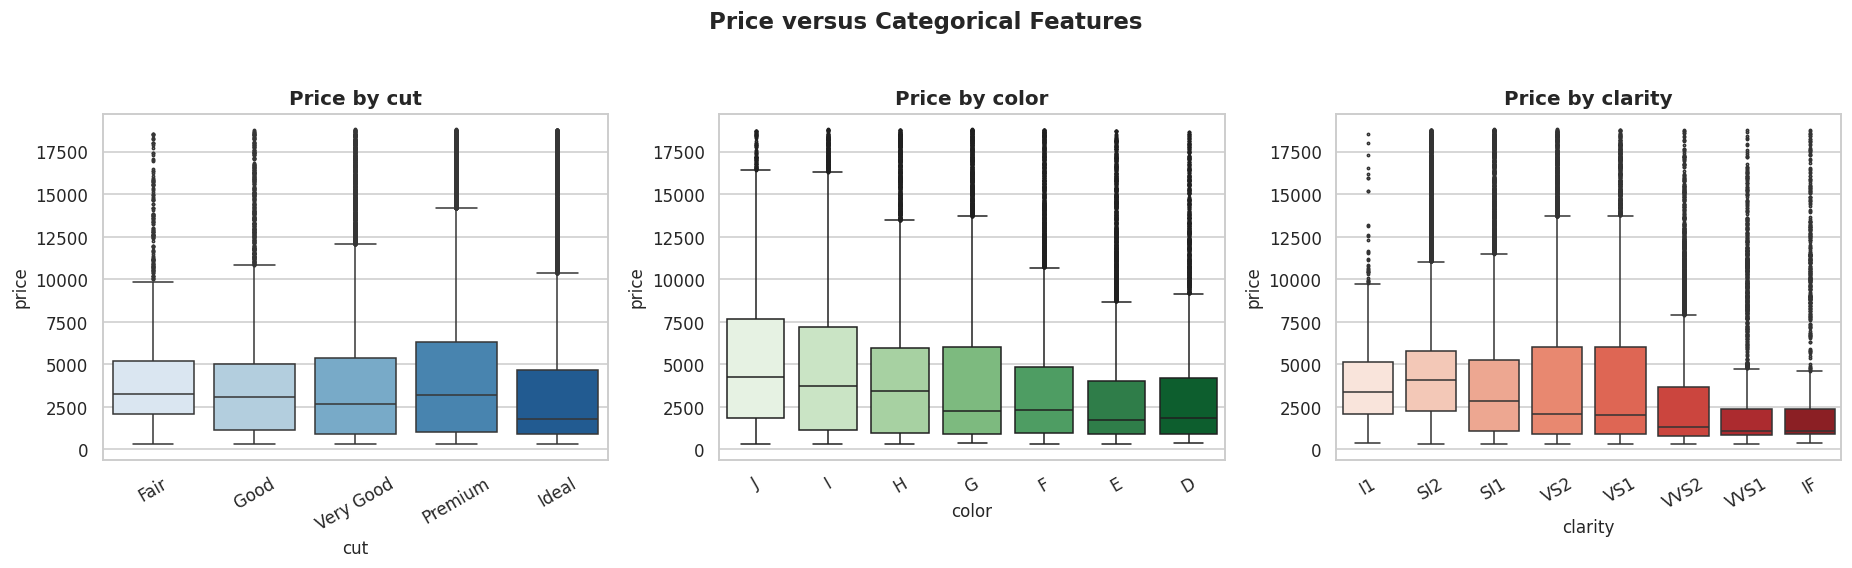

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, col, order, pal in zip(axes, ["cut", "color", "clarity"],
                               [cut_order, color_order, clarity_order],
                               ["Blues", "Greens", "Reds"]):
    sns.boxplot(data=df, x=col, y="price", order=order, palette=pal, ax=ax, fliersize=1.5)
    ax.set_title(f"Price by {col}")
    ax.tick_params(axis="x", rotation=30)
fig.suptitle("Price versus Categorical Features", fontsize=15, fontweight="bold", y=1.03)
fig.tight_layout()
save_fig(fig, "04_price_by_categorical")

### 3.4 Relationship Between Price and Numeric Features

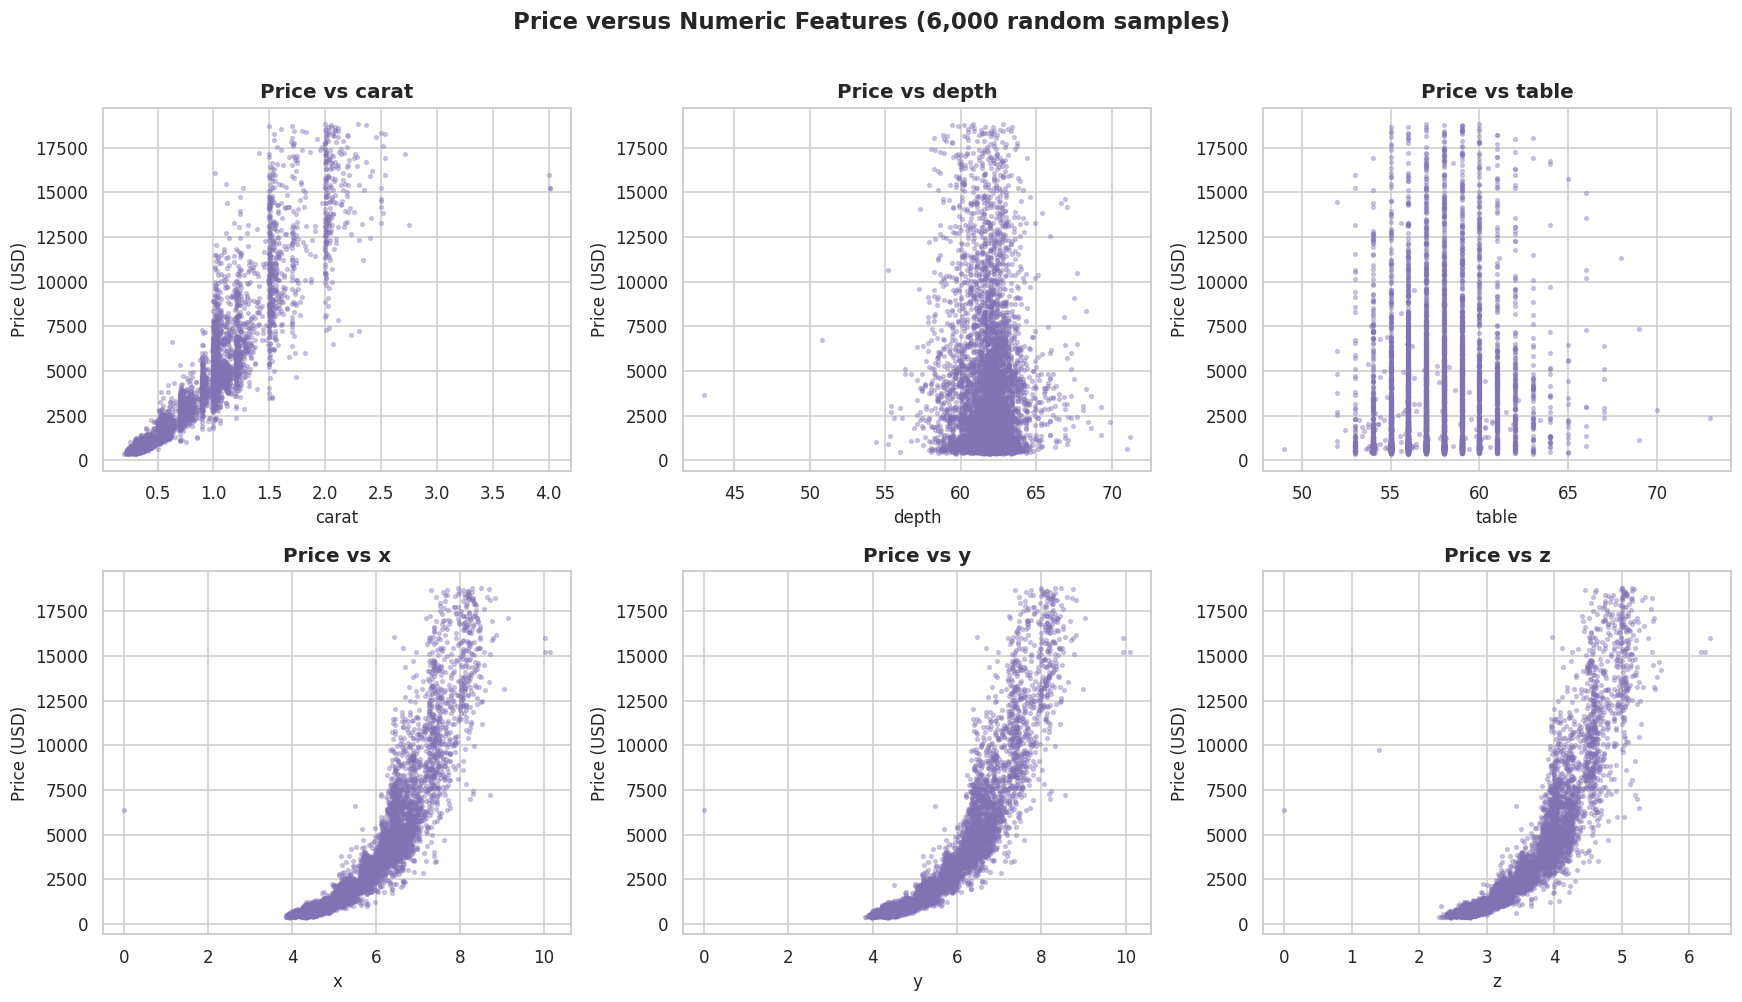

In [10]:
sample = df.sample(6000, random_state=SEED)
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.ravel(), num_cols):
    ax.scatter(sample[col], sample["price"], s=6, alpha=0.35, color="#8172B3")
    ax.set_title(f"Price vs {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Price (USD)")
fig.suptitle("Price versus Numeric Features (6,000 random samples)", fontsize=15, fontweight="bold", y=1.01)
fig.tight_layout()
save_fig(fig, "05_price_vs_numeric")

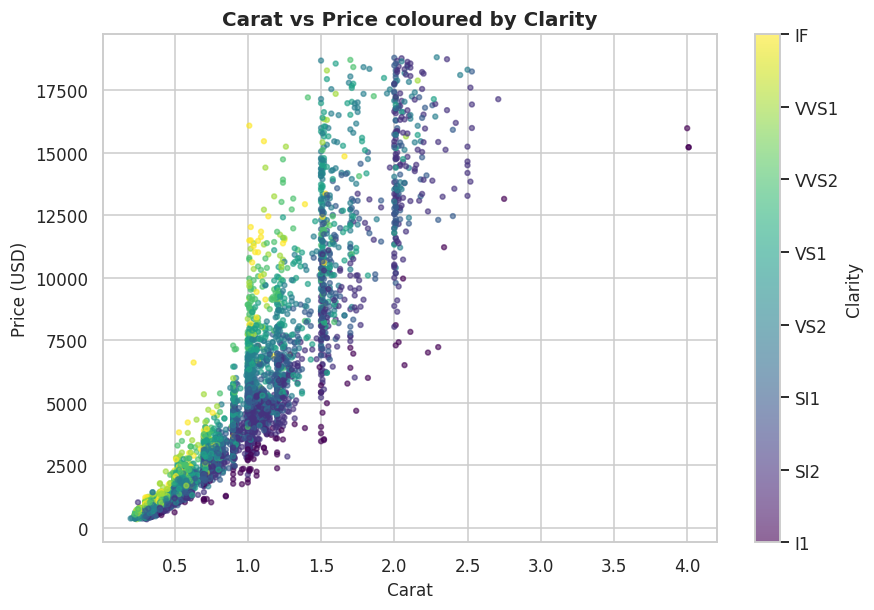

In [11]:
fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(sample["carat"], sample["price"], c=sample["clarity"].map({c: i for i, c in enumerate(clarity_order)}),
                cmap="viridis", s=10, alpha=0.6)
cbar = plt.colorbar(sc, ax=ax)
cbar.set_ticks(range(len(clarity_order)))
cbar.set_ticklabels(clarity_order)
cbar.set_label("Clarity")
ax.set_title("Carat vs Price coloured by Clarity")
ax.set_xlabel("Carat")
ax.set_ylabel("Price (USD)")
save_fig(fig, "06_carat_price_clarity")

## 4. Data Preprocessing

Steps applied:

1. Remove rows with impossible physical dimensions (x, y or z equal to 0) and extreme measurement errors (y > 20 mm or z > 20 mm).
2. Remove duplicate rows.
3. Encode the three ordered categorical columns (`cut`, `color`, `clarity`) as integers that respect their natural quality order (ordinal encoding).
4. Split the data into 80% training and 20% testing (same split for all six models).
5. Standardise features (zero mean, unit variance) using statistics of the training set only. Scaled data is used by Linear Regression, KNN and the Neural Network, because these are sensitive to feature scale. Tree-based models (Decision Tree, Random Forest, XGBoost) use the unscaled data.

In [12]:
data = df.copy()
before = len(data)
data = data[(data[["x", "y", "z"]] > 0).all(axis=1)]
data = data[(data["y"] < 20) & (data["z"] < 20)]
data = data.drop_duplicates().reset_index(drop=True)
print(f"Rows before: {before}  |  Rows after cleaning: {len(data)}  |  Removed: {before - len(data)}")

Rows before: 53940  |  Rows after cleaning: 53772  |  Removed: 168


In [13]:
data["cut"] = data["cut"].map({v: i for i, v in enumerate(cut_order)})
data["color"] = data["color"].map({v: i for i, v in enumerate(color_order)})
data["clarity"] = data["clarity"].map({v: i for i, v in enumerate(clarity_order)})
data.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,4,5,1,61.5,55.0,326,3.95,3.98,2.43
1,0.21,3,5,2,59.8,61.0,326,3.89,3.84,2.31
2,0.23,1,5,4,56.9,65.0,327,4.05,4.07,2.31
3,0.29,3,1,3,62.4,58.0,334,4.20,4.23,2.63
4,0.31,1,0,1,63.3,58.0,335,4.34,4.35,2.75


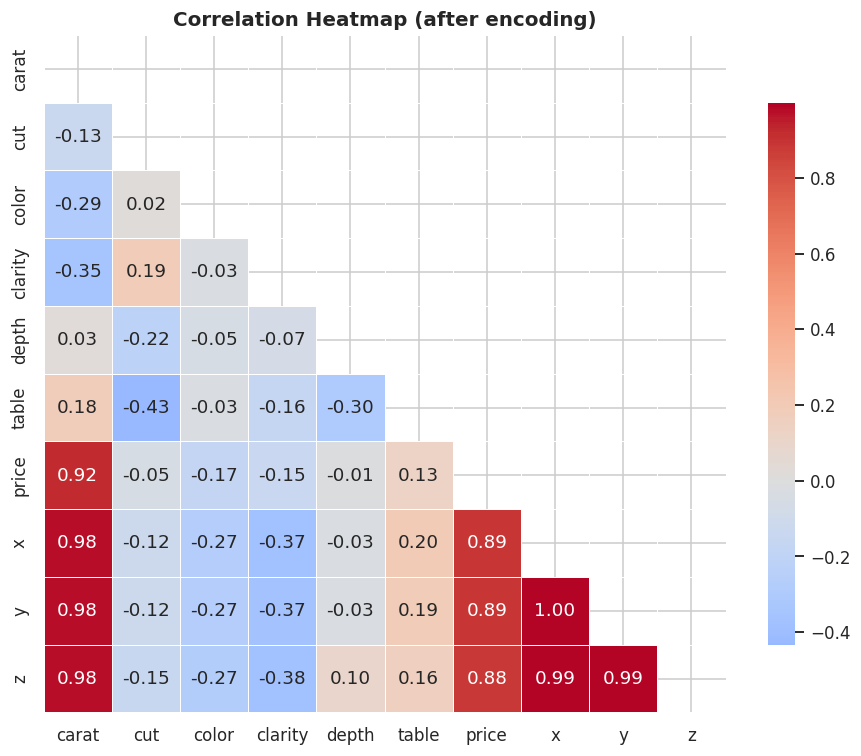

In [14]:
fig, ax = plt.subplots(figsize=(10, 8))
corr = data.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Correlation Heatmap (after encoding)")
save_fig(fig, "07_correlation_heatmap")

In [15]:
FEATURES = ["carat", "cut", "color", "clarity", "depth", "table", "x", "y", "z"]
TARGET = "price"

X = data[FEATURES]
y = data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED)

scaler_X = StandardScaler().fit(X_train)
X_train_s = scaler_X.transform(X_train)
X_test_s = scaler_X.transform(X_test)

print("Training samples:", X_train.shape[0], "(80%)")
print("Testing samples :", X_test.shape[0], "(20%)")
print("Number of features:", X_train.shape[1])

Training samples: 43017 (80%)
Testing samples : 10755 (20%)
Number of features: 9


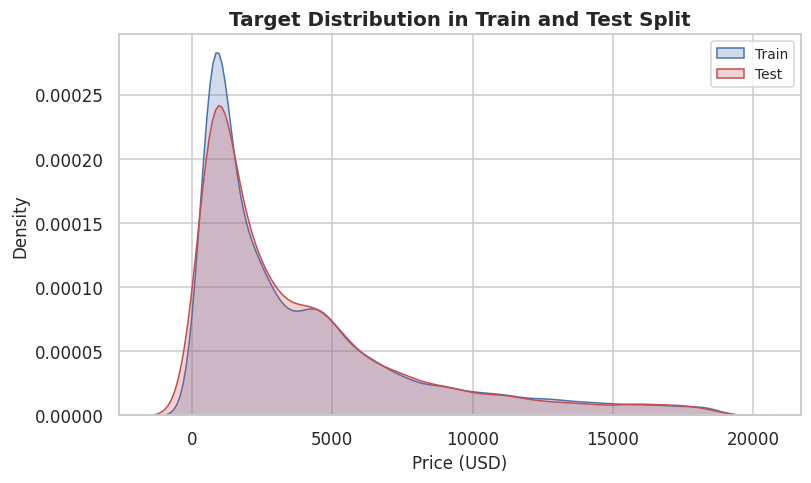

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.kdeplot(y_train, fill=True, color="#4C72B0", label="Train", ax=ax)
sns.kdeplot(y_test, fill=True, color="#C44E52", label="Test", ax=ax)
ax.set_title("Target Distribution in Train and Test Split")
ax.set_xlabel("Price (USD)")
ax.legend()
save_fig(fig, "08_train_test_distribution")

## 5. Evaluation Utilities

All models are evaluated on the same test set using:

- **MAE** = (1/n) Σ |yᵢ − ŷᵢ|
- **MSE** = (1/n) Σ (yᵢ − ŷᵢ)²
- **RMSE** = √MSE
- **R²** = 1 − Σ(yᵢ − ŷᵢ)² / Σ(yᵢ − ȳ)²

In [17]:
results = []
test_predictions = {}
train_r2 = {}
fit_times = {}

def evaluate(name, model_pred_test, model_pred_train, seconds):
    mae = mean_absolute_error(y_test, model_pred_test)
    mse = mean_squared_error(y_test, model_pred_test)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, model_pred_test)
    results.append({"Model": name, "MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2})
    test_predictions[name] = np.asarray(model_pred_test)
    train_r2[name] = r2_score(y_train, model_pred_train)
    fit_times[name] = seconds
    print(f"{name}")
    print(f"  MAE  : {mae:,.2f}")
    print(f"  MSE  : {mse:,.2f}")
    print(f"  RMSE : {rmse:,.2f}")
    print(f"  R2   : {r2:.4f}")
    print(f"  Train R2: {train_r2[name]:.4f}   |   Training time: {seconds:.2f} s")

def diagnostic_plots(name, fname):
    pred = test_predictions[name]
    resid = y_test.values - pred
    color = MODEL_COLORS[name]
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    ax = axes[0, 0]
    ax.scatter(y_test, pred, s=7, alpha=0.35, color=color)
    lim = [0, max(y_test.max(), pred.max())]
    ax.plot(lim, lim, "k--", lw=1.5, label="Perfect prediction")
    ax.set_title("Actual vs Predicted")
    ax.set_xlabel("Actual Price (USD)")
    ax.set_ylabel("Predicted Price (USD)")
    ax.legend()

    ax = axes[0, 1]
    ax.scatter(pred, resid, s=7, alpha=0.35, color=color)
    ax.axhline(0, color="k", ls="--", lw=1.5)
    ax.set_title("Residuals vs Predicted")
    ax.set_xlabel("Predicted Price (USD)")
    ax.set_ylabel("Residual (Actual - Predicted)")

    ax = axes[1, 0]
    sns.histplot(resid, bins=70, kde=True, color=color, ax=ax)
    ax.axvline(0, color="k", ls="--", lw=1.5)
    ax.set_title("Residual Distribution")
    ax.set_xlabel("Residual (USD)")

    ax = axes[1, 1]
    n = 100
    idx = np.arange(n)
    ax.plot(idx, y_test.values[:n], color="black", lw=1.8, marker="o", ms=3, label="Actual")
    ax.plot(idx, pred[:n], color=color, lw=1.8, marker="s", ms=3, label="Predicted")
    ax.set_title("First 100 Test Samples")
    ax.set_xlabel("Test sample index")
    ax.set_ylabel("Price (USD)")
    ax.legend()

    fig.suptitle(f"{name}: Prediction Diagnostics", fontsize=16, fontweight="bold", y=1.0)
    fig.tight_layout()
    save_fig(fig, fname)

## 6. Linear Regression

**Idea:** Assume the price is a weighted sum of the features and find the weights that minimise the squared error.

**Model:** ŷ = β₀ + β₁x₁ + β₂x₂ + … + β₉x₉

**Training (Ordinary Least Squares):** minimise J(β) = Σ (yᵢ − ŷᵢ)², which has the closed-form solution β = (XᵀX)⁻¹ Xᵀy.

**Scaling:** standardised features are used so that coefficients are directly comparable.

In [18]:
t0 = time.time()
lr = LinearRegression()
lr.fit(X_train_s, y_train)
sec = time.time() - t0

evaluate("Linear Regression", lr.predict(X_test_s), lr.predict(X_train_s), sec)

Linear Regression
  MAE  : 797.91
  MSE  : 1,478,169.73
  RMSE : 1,215.80
  R2   : 0.9048
  Train R2: 0.9089   |   Training time: 0.03 s


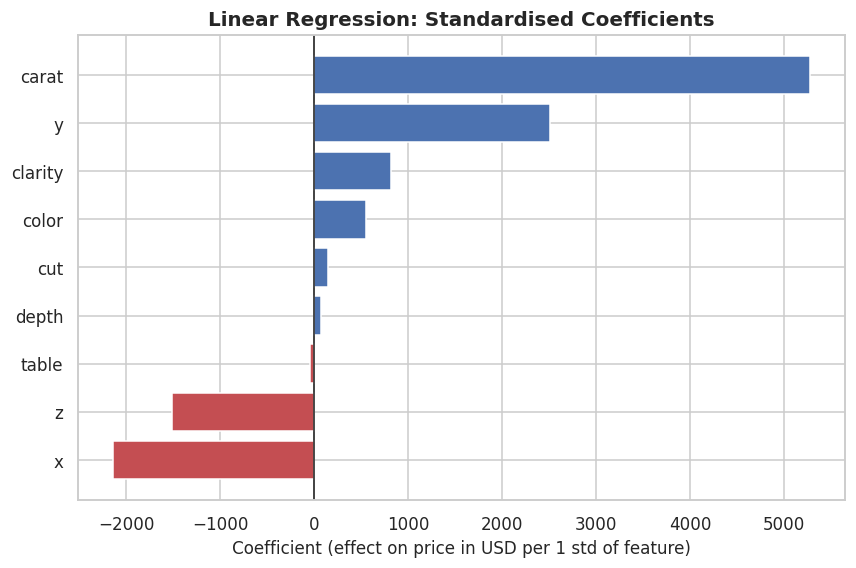

Intercept: 3938.49


In [19]:
coef = pd.Series(lr.coef_, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(9, 5.5))
colors = ["#C44E52" if v < 0 else "#4C72B0" for v in coef.values]
ax.barh(coef.index, coef.values, color=colors)
ax.axvline(0, color="k", lw=1)
ax.set_title("Linear Regression: Standardised Coefficients")
ax.set_xlabel("Coefficient (effect on price in USD per 1 std of feature)")
save_fig(fig, "09_lr_coefficients")
print("Intercept:", round(lr.intercept_, 2))

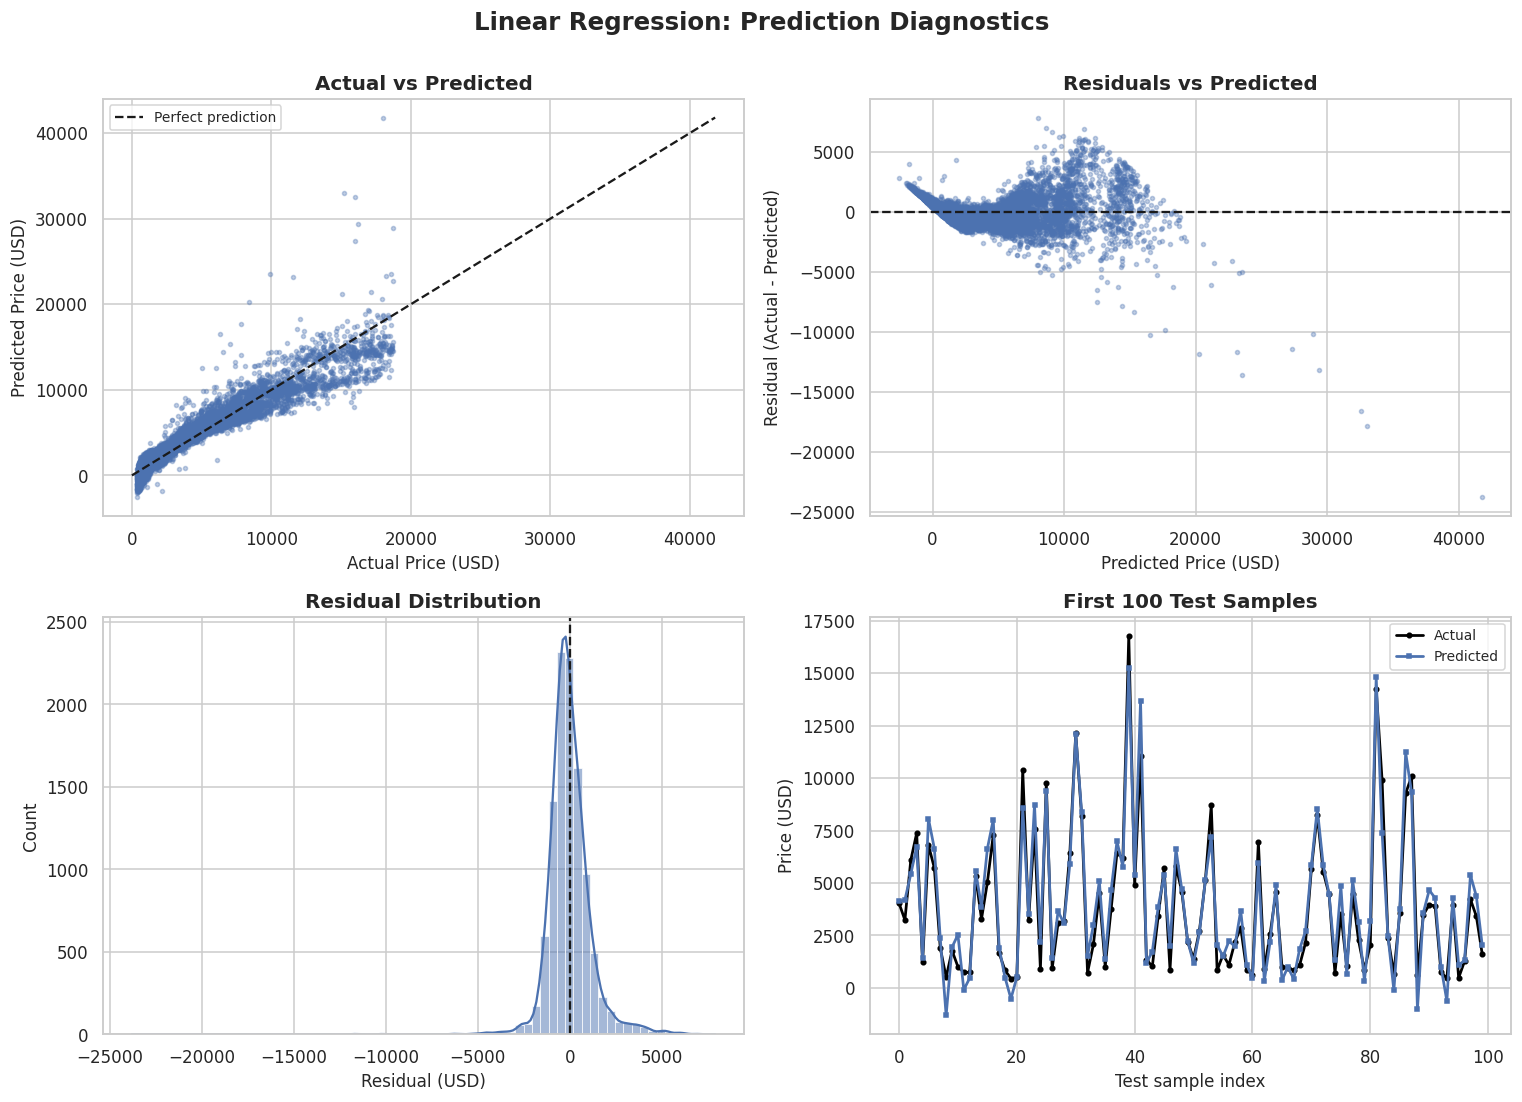

In [20]:
diagnostic_plots("Linear Regression", "10_lr_diagnostics")

## 7. Decision Tree Regression

**Idea:** Repeatedly split the data with yes/no questions on one feature, so that the samples inside each group have very similar prices. The prediction for a new sample is the average price of the leaf it falls into.

**Split criterion (variance / SSE reduction):** for a candidate split into left (L) and right (R) groups

Gain = SSE(parent) − [ SSE(L) + SSE(R) ],  where SSE(S) = Σ (yᵢ − ȳ_S)²

The split with the largest gain is chosen at every node. **Prediction:** ŷ = mean of the training prices in the leaf.

**Scaling:** not required for trees.

**Choosing the depth:** an unrestricted tree memorises the training data (overfitting). The depth is selected using 3-fold cross-validation on the training set only.

Best max_depth from cross-validation: 10


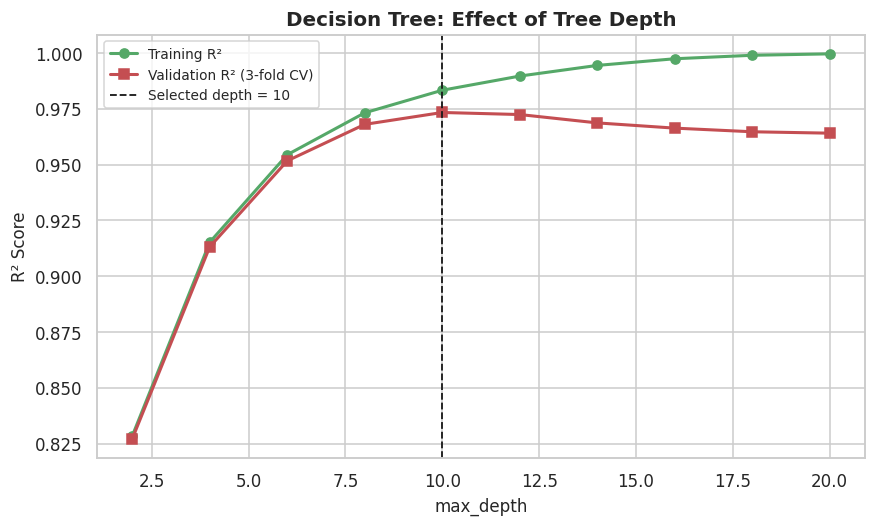

In [21]:
depths = list(range(2, 21, 2))
cv_train, cv_val = [], []
for d in depths:
    cv = cross_validate(DecisionTreeRegressor(max_depth=d, random_state=SEED), X_train, y_train,
                        cv=3, scoring="r2", return_train_score=True)
    cv_train.append(cv["train_score"].mean())
    cv_val.append(cv["test_score"].mean())

best_depth = depths[int(np.argmax(cv_val))]
print("Best max_depth from cross-validation:", best_depth)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(depths, cv_train, marker="o", color="#55A868", lw=2, label="Training R²")
ax.plot(depths, cv_val, marker="s", color="#C44E52", lw=2, label="Validation R² (3-fold CV)")
ax.axvline(best_depth, color="k", ls="--", lw=1.2, label=f"Selected depth = {best_depth}")
ax.set_title("Decision Tree: Effect of Tree Depth")
ax.set_xlabel("max_depth")
ax.set_ylabel("R² Score")
ax.legend()
save_fig(fig, "11_dt_depth_curve")

In [22]:
t0 = time.time()
dt = DecisionTreeRegressor(max_depth=best_depth, random_state=SEED)
dt.fit(X_train, y_train)
sec = time.time() - t0

evaluate("Decision Tree", dt.predict(X_test), dt.predict(X_train), sec)

Decision Tree
  MAE  : 332.63
  MSE  : 379,366.40
  RMSE : 615.93
  R2   : 0.9756
  Train R2: 0.9823   |   Training time: 0.19 s


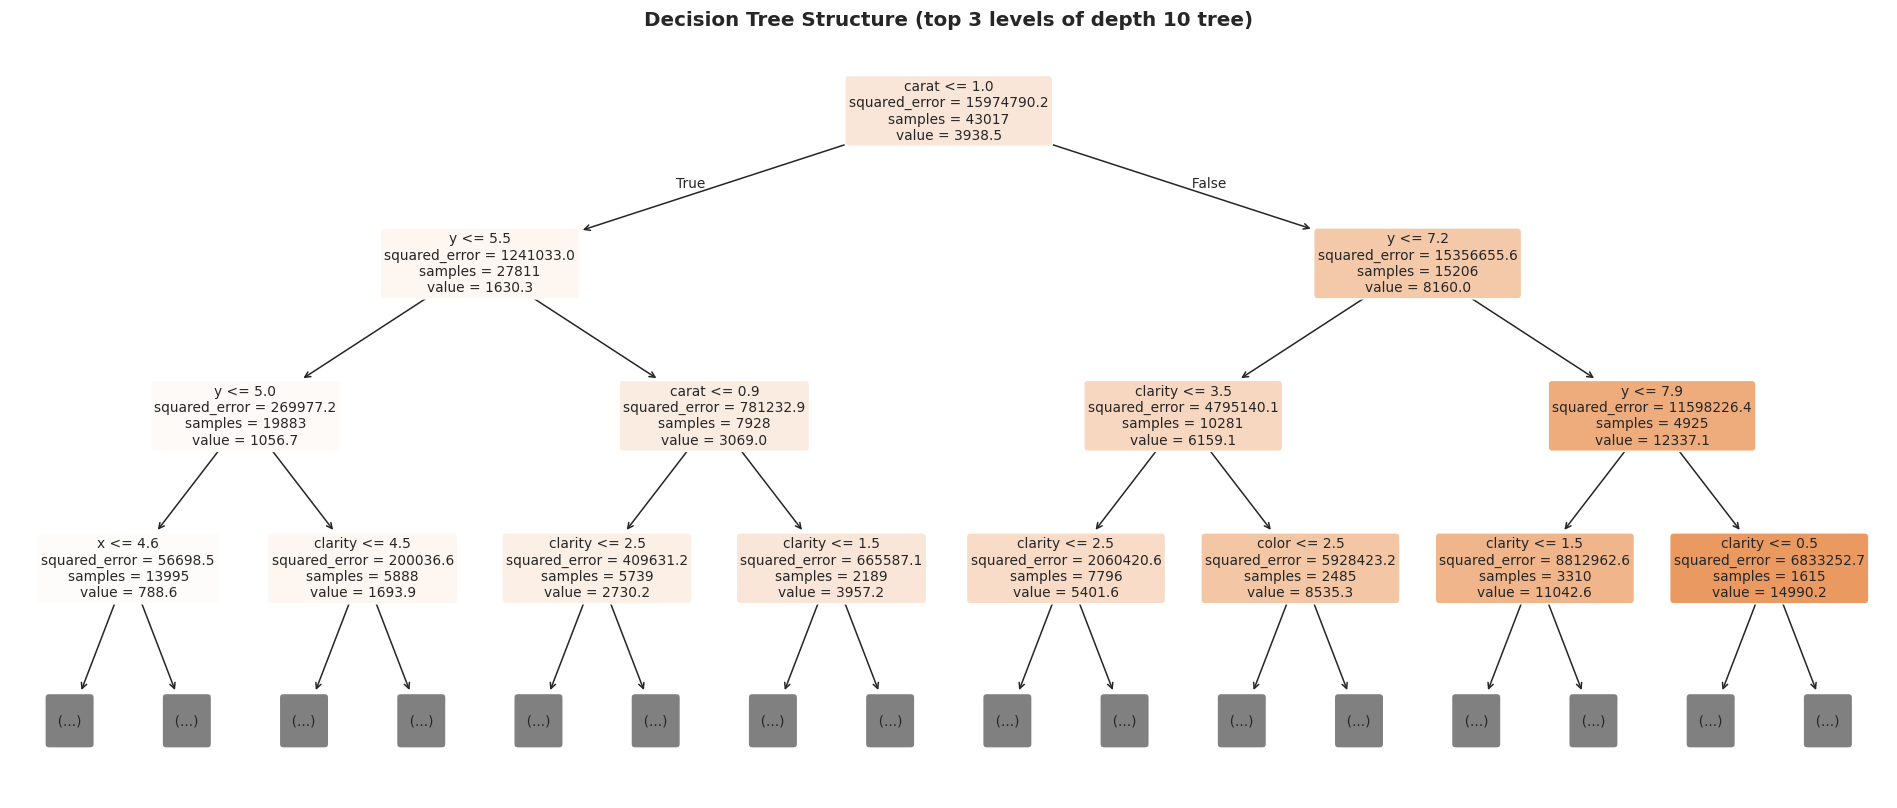

In [23]:
fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(dt, max_depth=3, feature_names=FEATURES, filled=True, rounded=True, fontsize=9, precision=1, ax=ax)
ax.set_title(f"Decision Tree Structure (top 3 levels of depth {best_depth} tree)")
save_fig(fig, "12_dt_tree_structure")

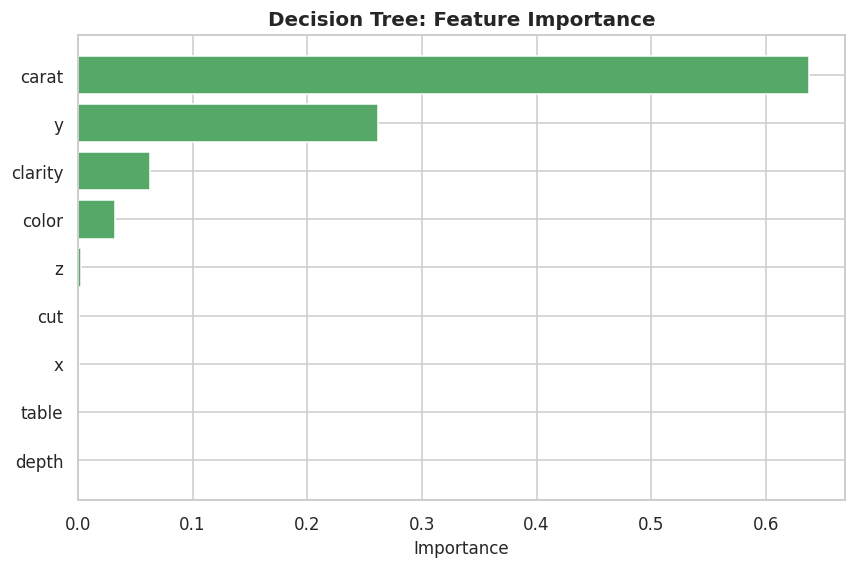

In [24]:
imp = pd.Series(dt.feature_importances_, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(imp.index, imp.values, color=MODEL_COLORS["Decision Tree"])
ax.set_title("Decision Tree: Feature Importance")
ax.set_xlabel("Importance")
save_fig(fig, "13_dt_feature_importance")

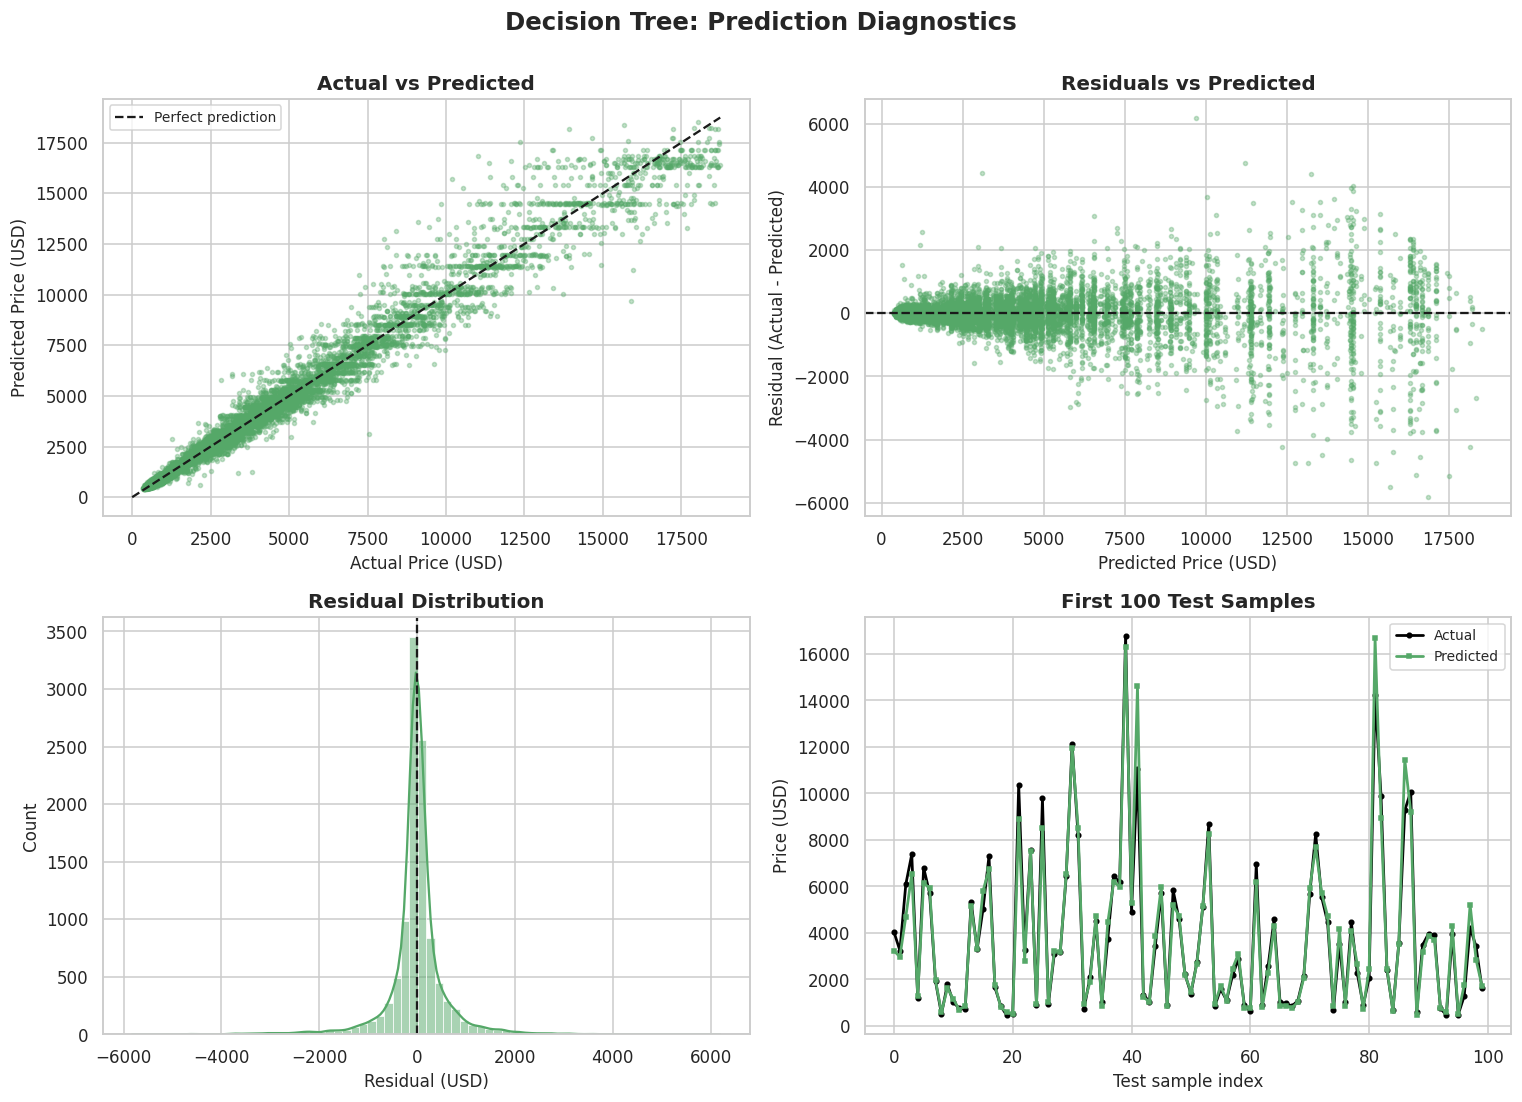

In [25]:
diagnostic_plots("Decision Tree", "14_dt_diagnostics")

## 8. Random Forest Regression

**Idea:** Build many decision trees, each on a different random bootstrap sample of the training data and each considering only a random subset of features at every split. The final prediction is the average of all tree predictions.

**Prediction:** ŷ = (1/T) Σ f_t(x), where T is the number of trees and f_t is the t-th tree.

**Why it works:** averaging many different high-variance trees reduces variance and overfitting compared with a single tree.

**Scaling:** not required.

In [26]:
t0 = time.time()
rf = RandomForestRegressor(n_estimators=200, max_features=0.6, min_samples_leaf=1,
                           n_jobs=-1, random_state=SEED)
rf.fit(X_train, y_train)
sec = time.time() - t0

evaluate("Random Forest", rf.predict(X_test), rf.predict(X_train), sec)

Random Forest
  MAE  : 263.03
  MSE  : 269,150.43
  RMSE : 518.80
  R2   : 0.9827
  Train R2: 0.9975   |   Training time: 29.49 s


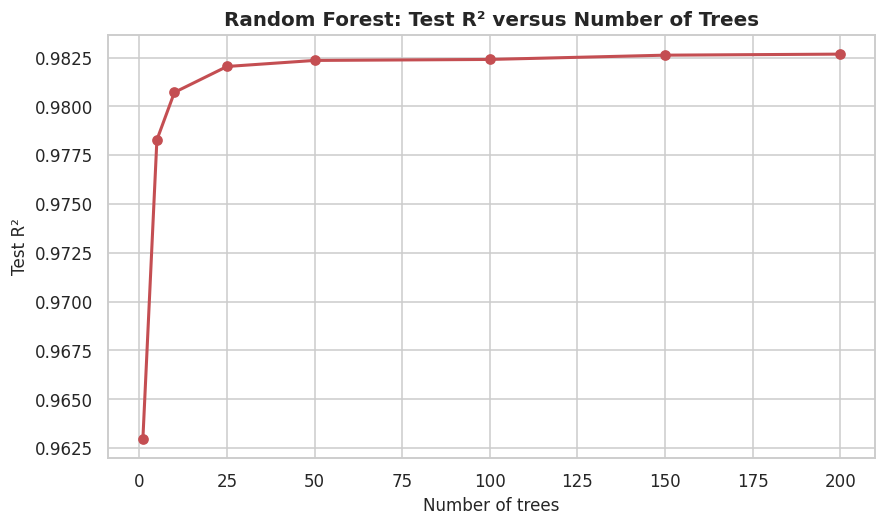

In [27]:
tree_counts = [1, 5, 10, 25, 50, 100, 150, 200]
growing = RandomForestRegressor(n_estimators=1, warm_start=True, max_features=0.6, n_jobs=-1, random_state=SEED)
curve = []
for n in tree_counts:
    growing.set_params(n_estimators=n)
    growing.fit(X_train, y_train)
    curve.append(r2_score(y_test, growing.predict(X_test)))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(tree_counts, curve, marker="o", lw=2, color=MODEL_COLORS["Random Forest"])
ax.set_title("Random Forest: Test R² versus Number of Trees")
ax.set_xlabel("Number of trees")
ax.set_ylabel("Test R²")
save_fig(fig, "15_rf_trees_curve")

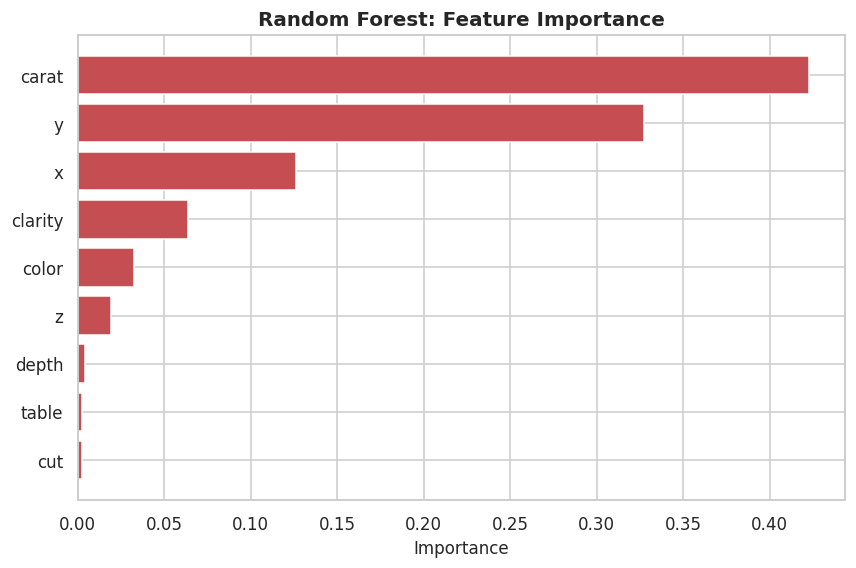

In [28]:
imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(imp.index, imp.values, color=MODEL_COLORS["Random Forest"])
ax.set_title("Random Forest: Feature Importance")
ax.set_xlabel("Importance")
save_fig(fig, "16_rf_feature_importance")

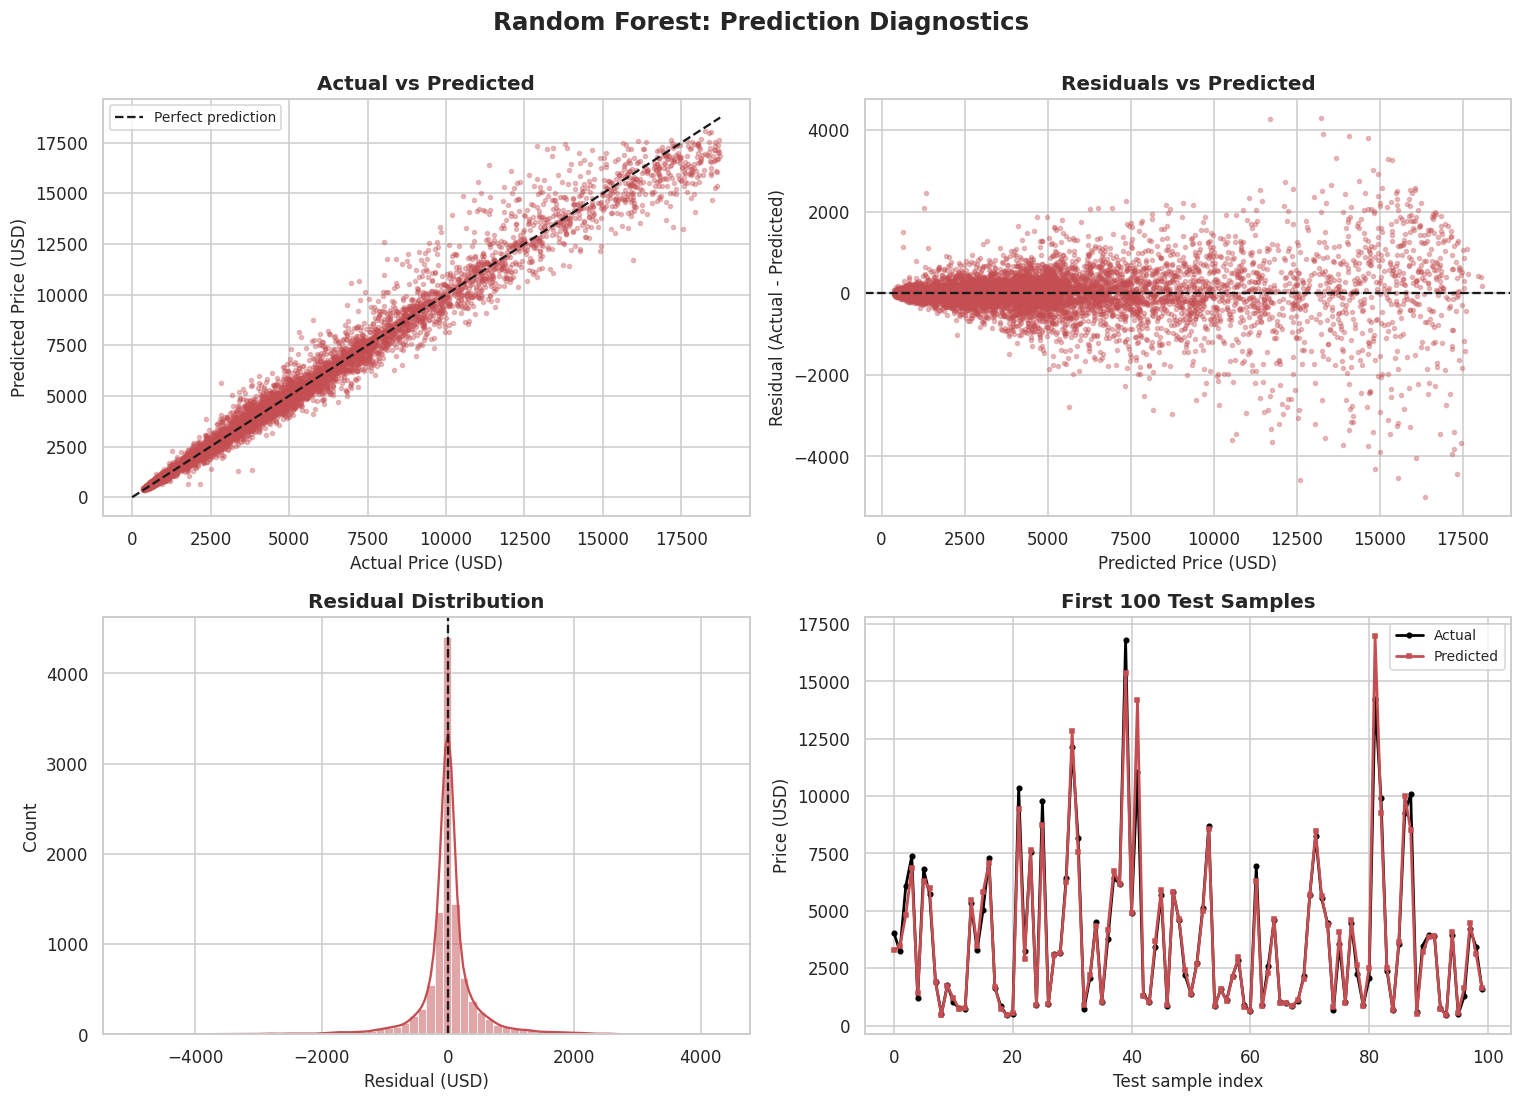

In [29]:
diagnostic_plots("Random Forest", "17_rf_diagnostics")

## 9. Neural Network Regression

**Idea:** A multi-layer perceptron passes the input through hidden layers of neurons. Every neuron computes a weighted sum of its inputs and applies a non-linear activation.

**Forward pass (per layer):** a = ReLU(W·x + b), where ReLU(z) = max(0, z).

**Output layer (regression):** ŷ = W_out · a + b_out (linear, no activation).

**Loss:** MSE = (1/n) Σ (yᵢ − ŷᵢ)².

**Training:** back-propagation computes ∂Loss/∂W for every weight and the Adam optimiser updates them: W ← W − η · ∂Loss/∂W.

**Architecture used:** 9 inputs → 128 → 64 → 32 → 1 output.

**Scaling:** required for both the inputs and the target (price) so that training is stable. Predictions are converted back to dollars.

In [30]:
scaler_y = StandardScaler().fit(y_train.values.reshape(-1, 1))
y_train_s = scaler_y.transform(y_train.values.reshape(-1, 1)).ravel()

t0 = time.time()
nn = MLPRegressor(hidden_layer_sizes=(128, 64, 32), activation="relu", solver="adam",
                  learning_rate_init=0.001, batch_size=256, max_iter=300,
                  early_stopping=True, validation_fraction=0.1, n_iter_no_change=15,
                  random_state=SEED)
nn.fit(X_train_s, y_train_s)
sec = time.time() - t0

pred_test_nn = scaler_y.inverse_transform(nn.predict(X_test_s).reshape(-1, 1)).ravel()
pred_train_nn = scaler_y.inverse_transform(nn.predict(X_train_s).reshape(-1, 1)).ravel()
evaluate("Neural Network", pred_test_nn, pred_train_nn, sec)
print("Epochs run:", nn.n_iter_)

Neural Network
  MAE  : 289.44
  MSE  : 282,899.48
  RMSE : 531.88
  R2   : 0.9818
  Train R2: 0.9831   |   Training time: 26.55 s
Epochs run: 46


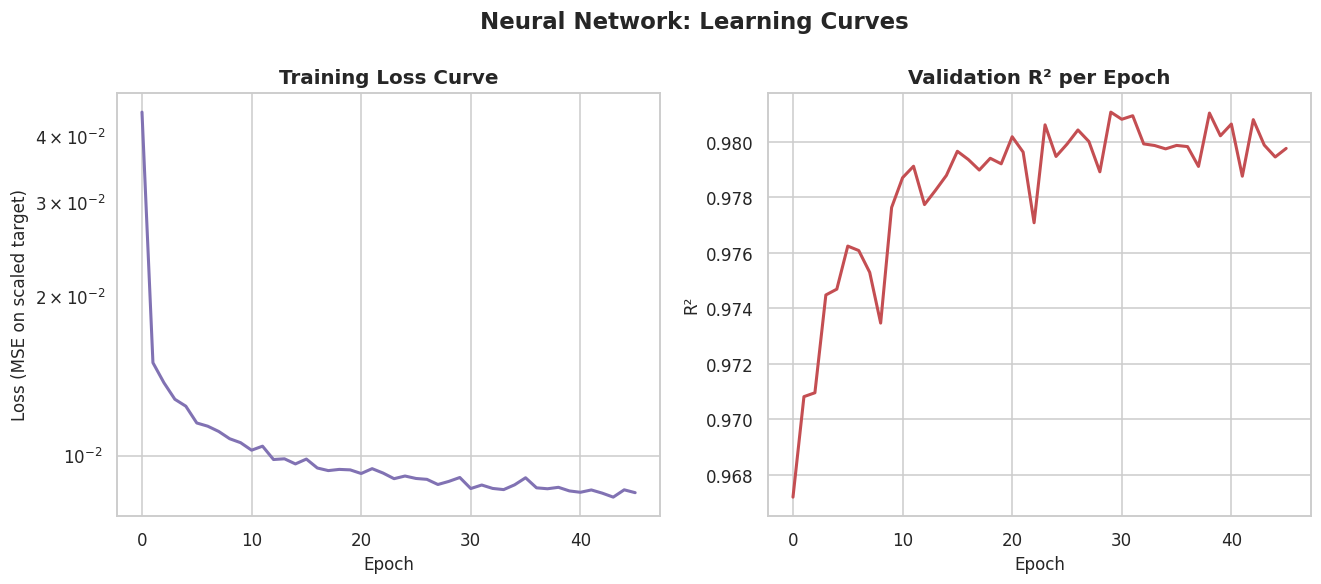

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(nn.loss_curve_, color=MODEL_COLORS["Neural Network"], lw=2)
axes[0].set_title("Training Loss Curve")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss (MSE on scaled target)")
axes[0].set_yscale("log")
axes[1].plot(nn.validation_scores_, color="#C44E52", lw=2)
axes[1].set_title("Validation R² per Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("R²")
fig.suptitle("Neural Network: Learning Curves", fontsize=15, fontweight="bold", y=1.03)
save_fig(fig, "18_nn_learning_curves")

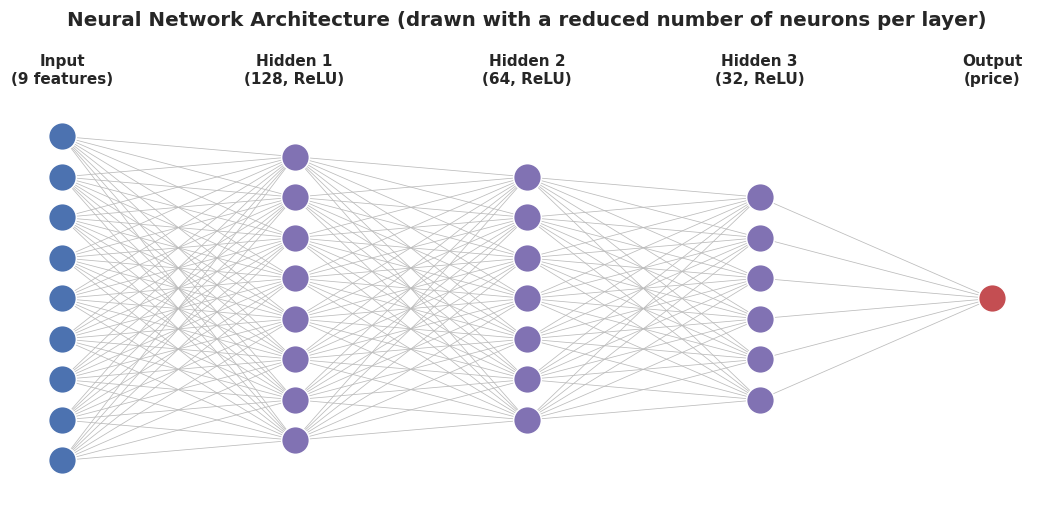

In [32]:
layers = [9, 128, 64, 32, 1]
names = ["Input\n(9 features)", "Hidden 1\n(128, ReLU)", "Hidden 2\n(64, ReLU)", "Hidden 3\n(32, ReLU)", "Output\n(price)"]
shown = [9, 8, 7, 6, 1]
fig, ax = plt.subplots(figsize=(12, 5.5))
pos = []
for li, n in enumerate(shown):
    ys = np.linspace(-(n - 1) / 2, (n - 1) / 2, n)
    pos.append([(li * 2.5, y) for y in ys])
for li in range(len(pos) - 1):
    for (x1, y1) in pos[li]:
        for (x2, y2) in pos[li + 1]:
            ax.plot([x1, x2], [y1, y2], color="#BBBBBB", lw=0.5, zorder=1)
for li, layer in enumerate(pos):
    for (x, yv) in layer:
        ax.scatter(x, yv, s=330, color=["#4C72B0", "#8172B3", "#8172B3", "#8172B3", "#C44E52"][li], zorder=2, edgecolor="white")
    ax.text(layer[0][0], 5.3, names[li], ha="center", fontsize=10, fontweight="bold")
ax.set_ylim(-5, 6.5)
ax.axis("off")
ax.set_title("Neural Network Architecture (drawn with a reduced number of neurons per layer)")
save_fig(fig, "19_nn_architecture")

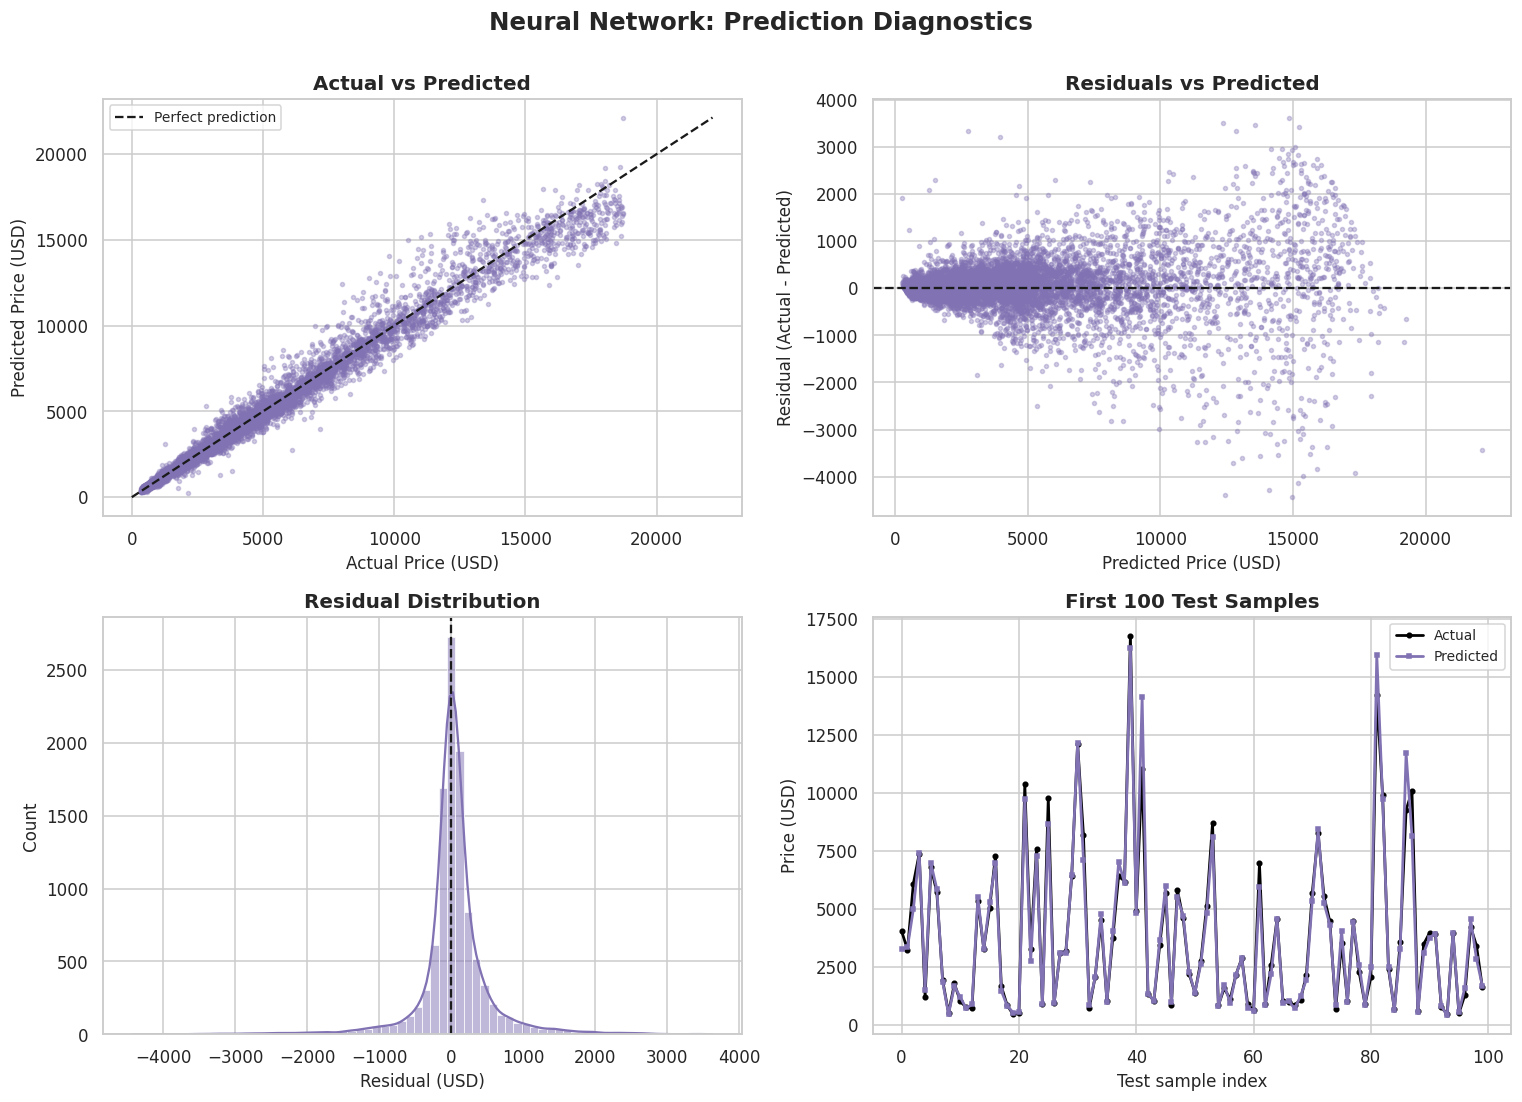

In [33]:
test_predictions["Neural Network"] = pred_test_nn
diagnostic_plots("Neural Network", "20_nn_diagnostics")

## 10. XGBoost Regression

**Idea:** Gradient boosting builds trees one after another. Each new tree is trained to correct the errors (residuals) of all previous trees.

**Prediction after t rounds:** ŷ⁽ᵗ⁾ = ŷ⁽ᵗ⁻¹⁾ + η · f_t(x), where η is the learning rate.

**Objective at each round:** Σ L(yᵢ, ŷᵢ) + Ω(f), with squared-error loss and regularisation Ω(f) = γT + ½λΣw².

For squared error the gradient is gᵢ = ŷᵢ − yᵢ and the Hessian is hᵢ = 1.

**Optimal leaf weight:** w* = − Σg / (Σh + λ)

**Split gain:** Gain = ½ [ G_L²/(H_L+λ) + G_R²/(H_R+λ) − (G_L+G_R)²/(H_L+H_R+λ) ] − γ

**Scaling:** not required.

In [34]:
t0 = time.time()
xgb = XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=6, subsample=0.8,
                   colsample_bytree=0.8, reg_lambda=1.0, objective="reg:squarederror",
                   n_jobs=-1, random_state=SEED)
xgb.fit(X_train, y_train, eval_set=[(X_train, y_train), (X_test, y_test)], verbose=False)
sec = time.time() - t0

evaluate("XGBoost", xgb.predict(X_test), xgb.predict(X_train), sec)

XGBoost
  MAE  : 268.39
  MSE  : 265,281.78
  RMSE : 515.06
  R2   : 0.9829
  Train R2: 0.9917   |   Training time: 7.82 s


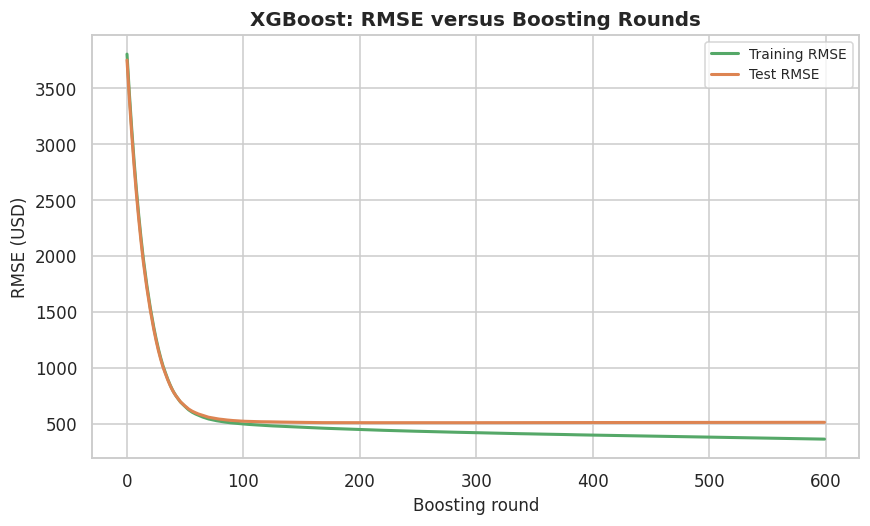

In [35]:
hist = xgb.evals_result()
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(hist["validation_0"]["rmse"], lw=2, color="#55A868", label="Training RMSE")
ax.plot(hist["validation_1"]["rmse"], lw=2, color="#DD8452", label="Test RMSE")
ax.set_title("XGBoost: RMSE versus Boosting Rounds")
ax.set_xlabel("Boosting round")
ax.set_ylabel("RMSE (USD)")
ax.legend()
save_fig(fig, "21_xgb_learning_curve")

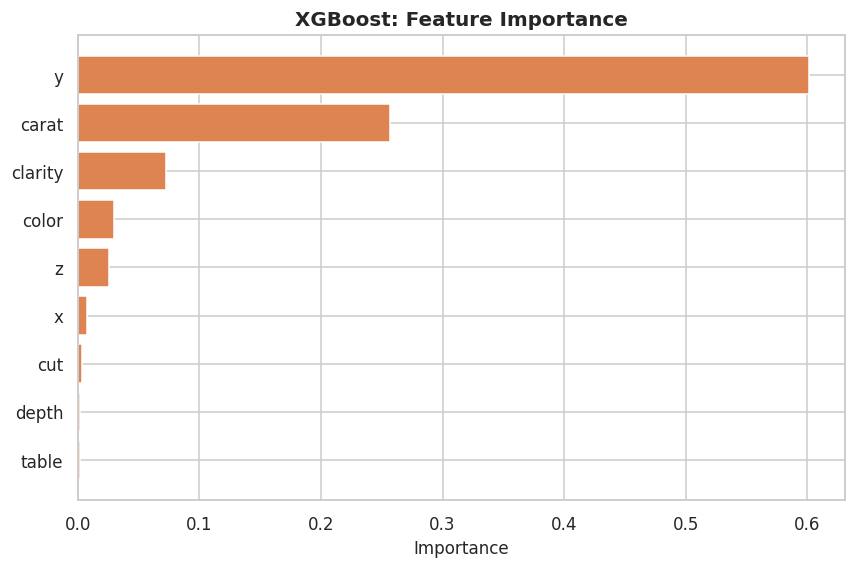

In [36]:
imp = pd.Series(xgb.feature_importances_, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(imp.index, imp.values, color=MODEL_COLORS["XGBoost"])
ax.set_title("XGBoost: Feature Importance")
ax.set_xlabel("Importance")
save_fig(fig, "22_xgb_feature_importance")

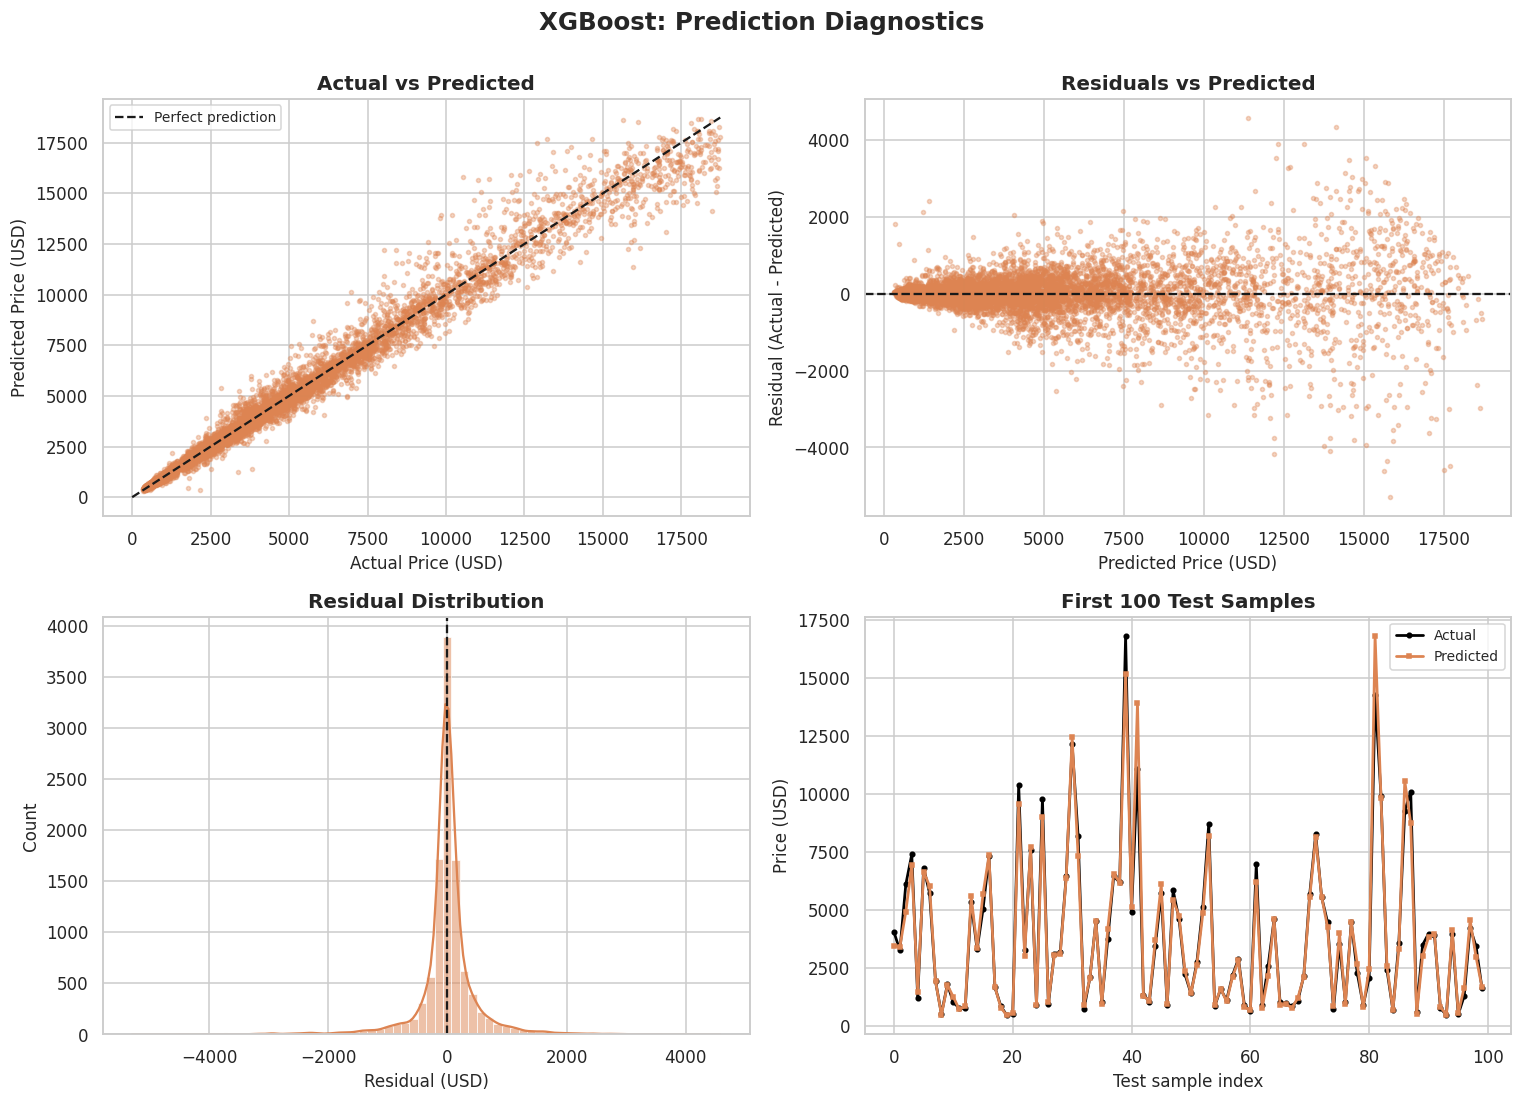

In [37]:
diagnostic_plots("XGBoost", "23_xgb_diagnostics")

## 11. K-Nearest Neighbors (KNN) Regression

**Idea:** To predict the price of a new diamond, find the K most similar diamonds in the training set and average their prices. No model is learned during training; the training data itself is the model.

**Distance (Euclidean):** d(a, b) = √ Σ (aⱼ − bⱼ)²

**Prediction:** ŷ = (1/K) Σ yᵢ over the K nearest neighbours.

**Scaling:** essential, because distance is dominated by features with large numeric ranges.

**Choosing K:** the value of K is selected with 3-fold cross-validation on the training set.

Best K from cross-validation: 9


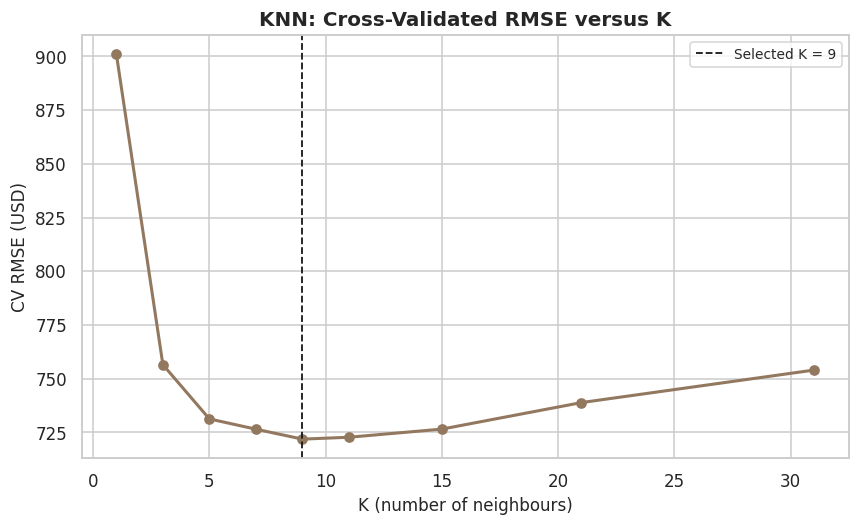

In [38]:
k_values = [1, 3, 5, 7, 9, 11, 15, 21, 31]
k_rmse = []
for k in k_values:
    cv = cross_validate(KNeighborsRegressor(n_neighbors=k, n_jobs=-1), X_train_s, y_train,
                        cv=3, scoring="neg_root_mean_squared_error")
    k_rmse.append(-cv["test_score"].mean())

best_k = k_values[int(np.argmin(k_rmse))]
print("Best K from cross-validation:", best_k)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(k_values, k_rmse, marker="o", lw=2, color=MODEL_COLORS["KNN"])
ax.axvline(best_k, color="k", ls="--", lw=1.2, label=f"Selected K = {best_k}")
ax.set_title("KNN: Cross-Validated RMSE versus K")
ax.set_xlabel("K (number of neighbours)")
ax.set_ylabel("CV RMSE (USD)")
ax.legend()
save_fig(fig, "24_knn_k_curve")

In [39]:
t0 = time.time()
knn = KNeighborsRegressor(n_neighbors=best_k, weights="uniform", n_jobs=-1)
knn.fit(X_train_s, y_train)
sec = time.time() - t0

evaluate("KNN", knn.predict(X_test_s), knn.predict(X_train_s), sec)

KNN
  MAE  : 374.72
  MSE  : 493,922.42
  RMSE : 702.80
  R2   : 0.9682
  Train R2: 0.9755   |   Training time: 0.07 s


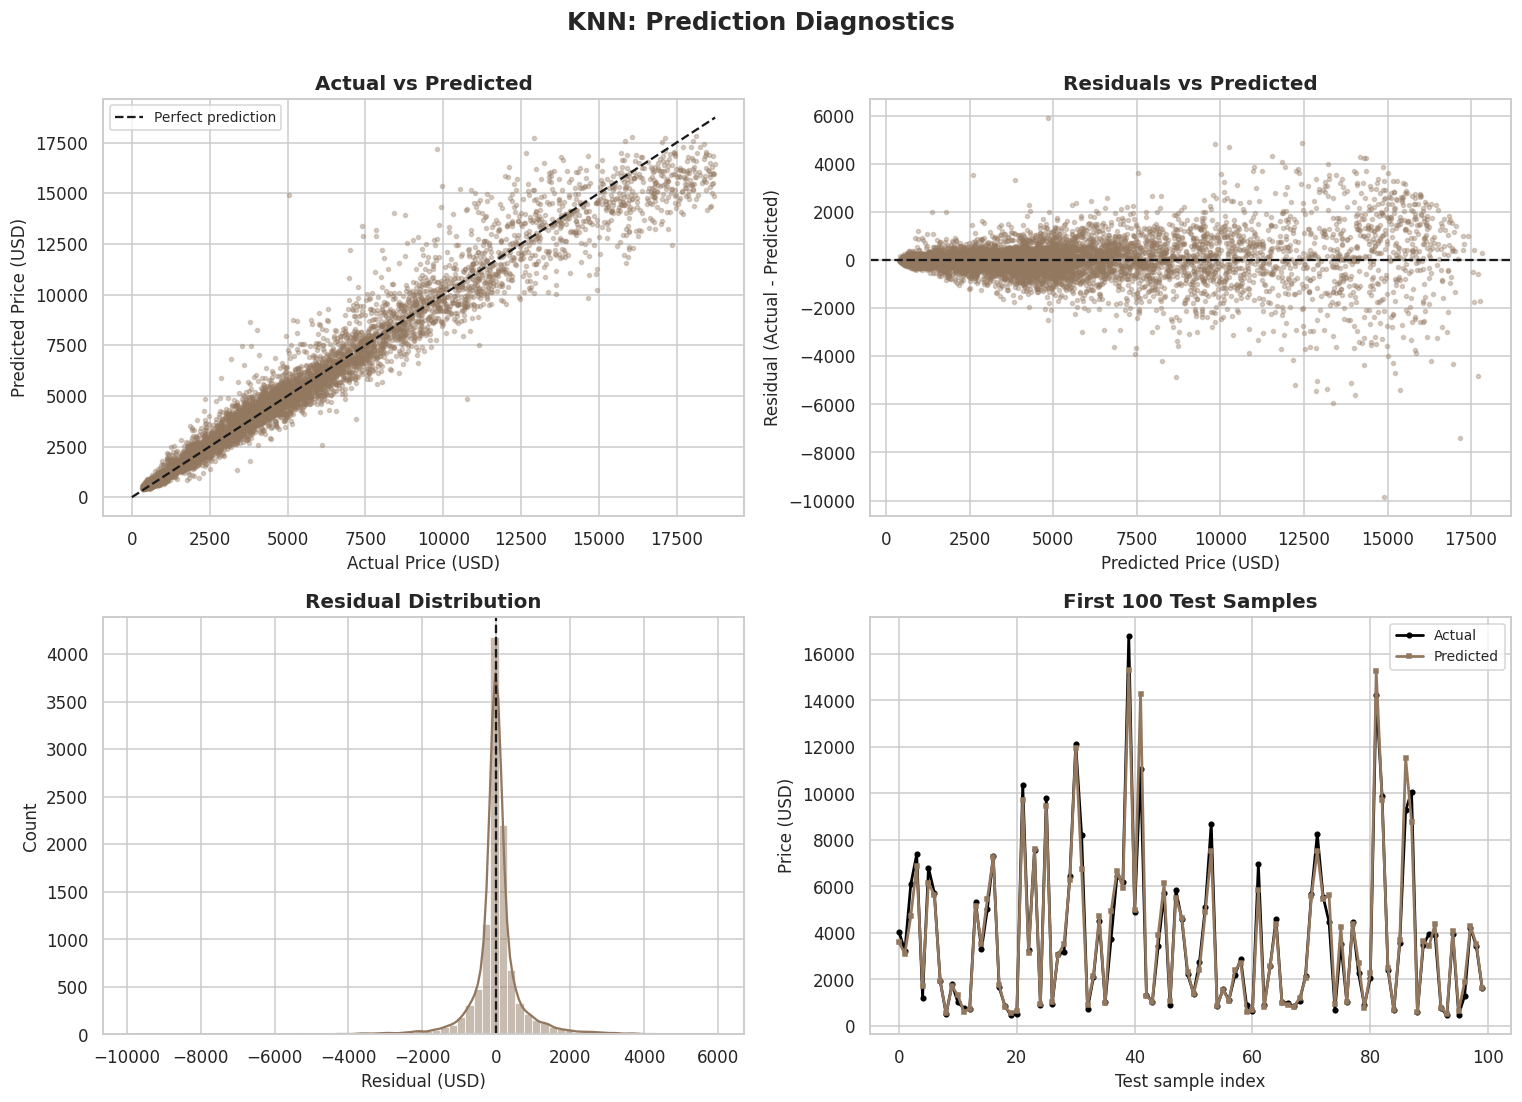

In [40]:
diagnostic_plots("KNN", "25_knn_diagnostics")

## 12. Comparative Performance of All Six Models

### 12.1 Performance Table

In [41]:
order = ["Linear Regression", "Decision Tree", "Random Forest", "Neural Network", "XGBoost", "KNN"]
res = pd.DataFrame(results).set_index("Model").loc[order]
res["Train R2"] = pd.Series(train_r2)
res["Train Time (s)"] = pd.Series(fit_times)
res.to_csv(f"{ASSETS}/comparison_results.csv")

styled = (res.style
          .format({"MAE": "{:,.2f}", "MSE": "{:,.0f}", "RMSE": "{:,.2f}", "R2": "{:.4f}",
                   "Train R2": "{:.4f}", "Train Time (s)": "{:.2f}"})
          .background_gradient(subset=["MAE", "MSE", "RMSE"], cmap="RdYlGn_r")
          .background_gradient(subset=["R2"], cmap="RdYlGn")
          .set_caption("Test-set performance (80:20 split, same features and target)"))
styled

,MAE,MSE,RMSE,R2,Train R2,Train Time (s)
Model,,,,,,
Linear Regression,797.91,"1,478,170","1,215.80",0.9048,0.9089,0.03
Decision Tree,332.63,"379,366",615.93,0.9756,0.9823,0.19
Random Forest,263.03,"269,150",518.80,0.9827,0.9975,29.49
Neural Network,289.44,"282,899",531.88,0.9818,0.9831,26.55
XGBoost,268.39,"265,282",515.06,0.9829,0.9917,7.82
KNN,374.72,"493,922",702.80,0.9682,0.9755,0.07


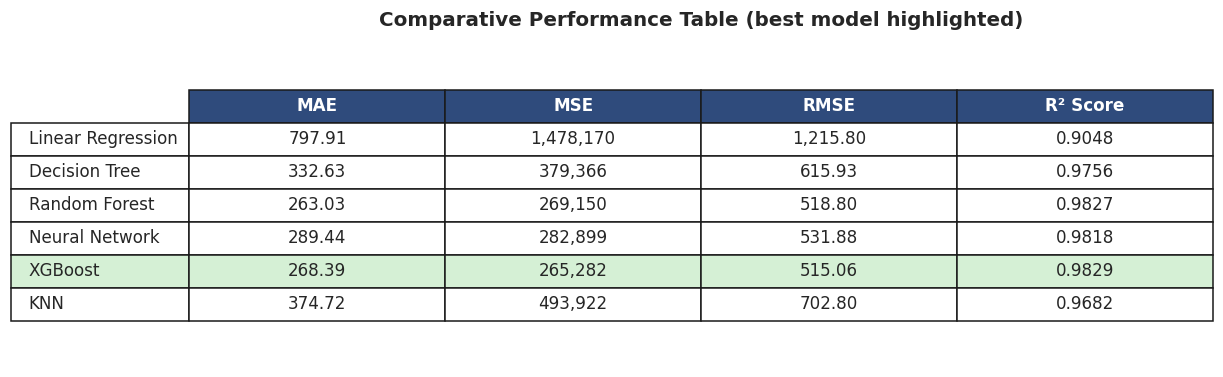

In [42]:
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.axis("off")
cell_text = [[f"{r.MAE:,.2f}", f"{r.MSE:,.0f}", f"{r.RMSE:,.2f}", f"{r.R2:.4f}"] for r in res.itertuples()]
table = ax.table(cellText=cell_text, rowLabels=res.index, colLabels=["MAE", "MSE", "RMSE", "R² Score"],
                 loc="center", cellLoc="center")
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 1.8)
best_row = res["RMSE"].values.argmin()
for (r, c), cell in table.get_celld().items():
    if r == 0:
        cell.set_facecolor("#2F4B7C")
        cell.set_text_props(color="white", fontweight="bold")
    elif r == best_row + 1:
        cell.set_facecolor("#D5F0D5")
ax.set_title("Comparative Performance Table (best model highlighted)", fontweight="bold", pad=12)
save_fig(fig, "26_comparison_table")

### 12.2 Metric Comparison Charts

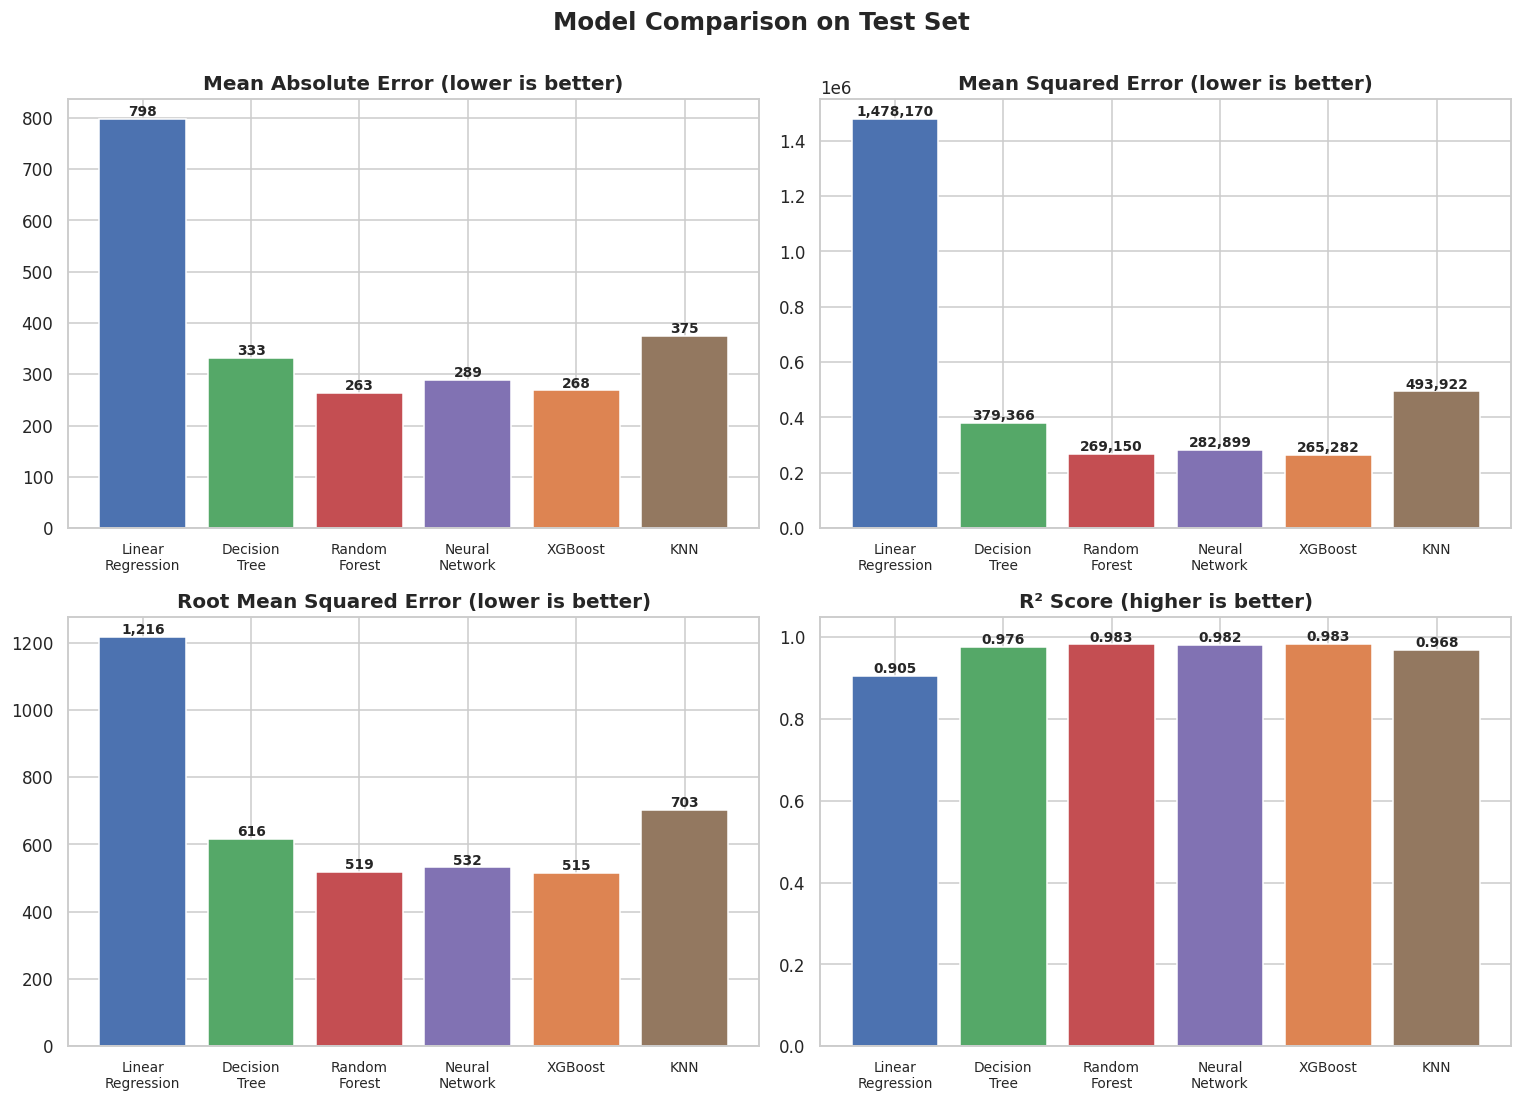

In [43]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
metrics = [("MAE", "Mean Absolute Error (lower is better)"),
           ("MSE", "Mean Squared Error (lower is better)"),
           ("RMSE", "Root Mean Squared Error (lower is better)"),
           ("R2", "R² Score (higher is better)")]
for ax, (m, title) in zip(axes.ravel(), metrics):
    vals = res[m]
    bars = ax.bar(range(len(vals)), vals.values, color=[MODEL_COLORS[n] for n in vals.index], edgecolor="white")
    ax.set_xticks(range(len(vals)))
    ax.set_xticklabels([n.replace(" ", "\n") for n in vals.index], fontsize=9)
    ax.set_title(title)
    for b, v in zip(bars, vals.values):
        txt = f"{v:.3f}" if m == "R2" else (f"{v:,.0f}")
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), txt, ha="center", va="bottom", fontsize=9, fontweight="bold")
    if m == "R2":
        ax.set_ylim(min(0.0, vals.min() - 0.05), 1.05)
fig.suptitle("Model Comparison on Test Set", fontsize=16, fontweight="bold", y=1.0)
fig.tight_layout()
save_fig(fig, "27_metric_comparison")

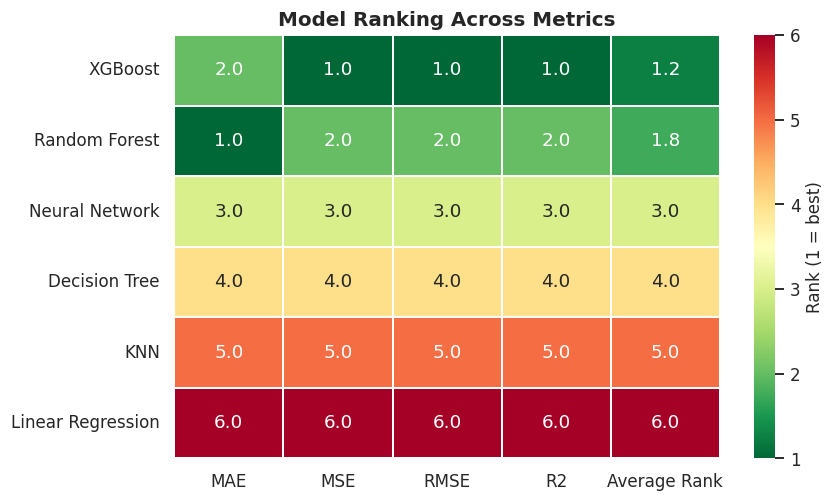

In [44]:
rank_df = pd.DataFrame({
    "MAE": res["MAE"].rank(),
    "MSE": res["MSE"].rank(),
    "RMSE": res["RMSE"].rank(),
    "R2": res["R2"].rank(ascending=False),
})
rank_df["Average Rank"] = rank_df.mean(axis=1)
rank_df = rank_df.sort_values("Average Rank")

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(rank_df, annot=True, fmt=".1f", cmap="RdYlGn_r", linewidths=1, cbar_kws={"label": "Rank (1 = best)"}, ax=ax)
ax.set_title("Model Ranking Across Metrics")
ax.set_ylabel("")
save_fig(fig, "28_rank_heatmap")

### 12.3 Actual versus Predicted Values for All Models

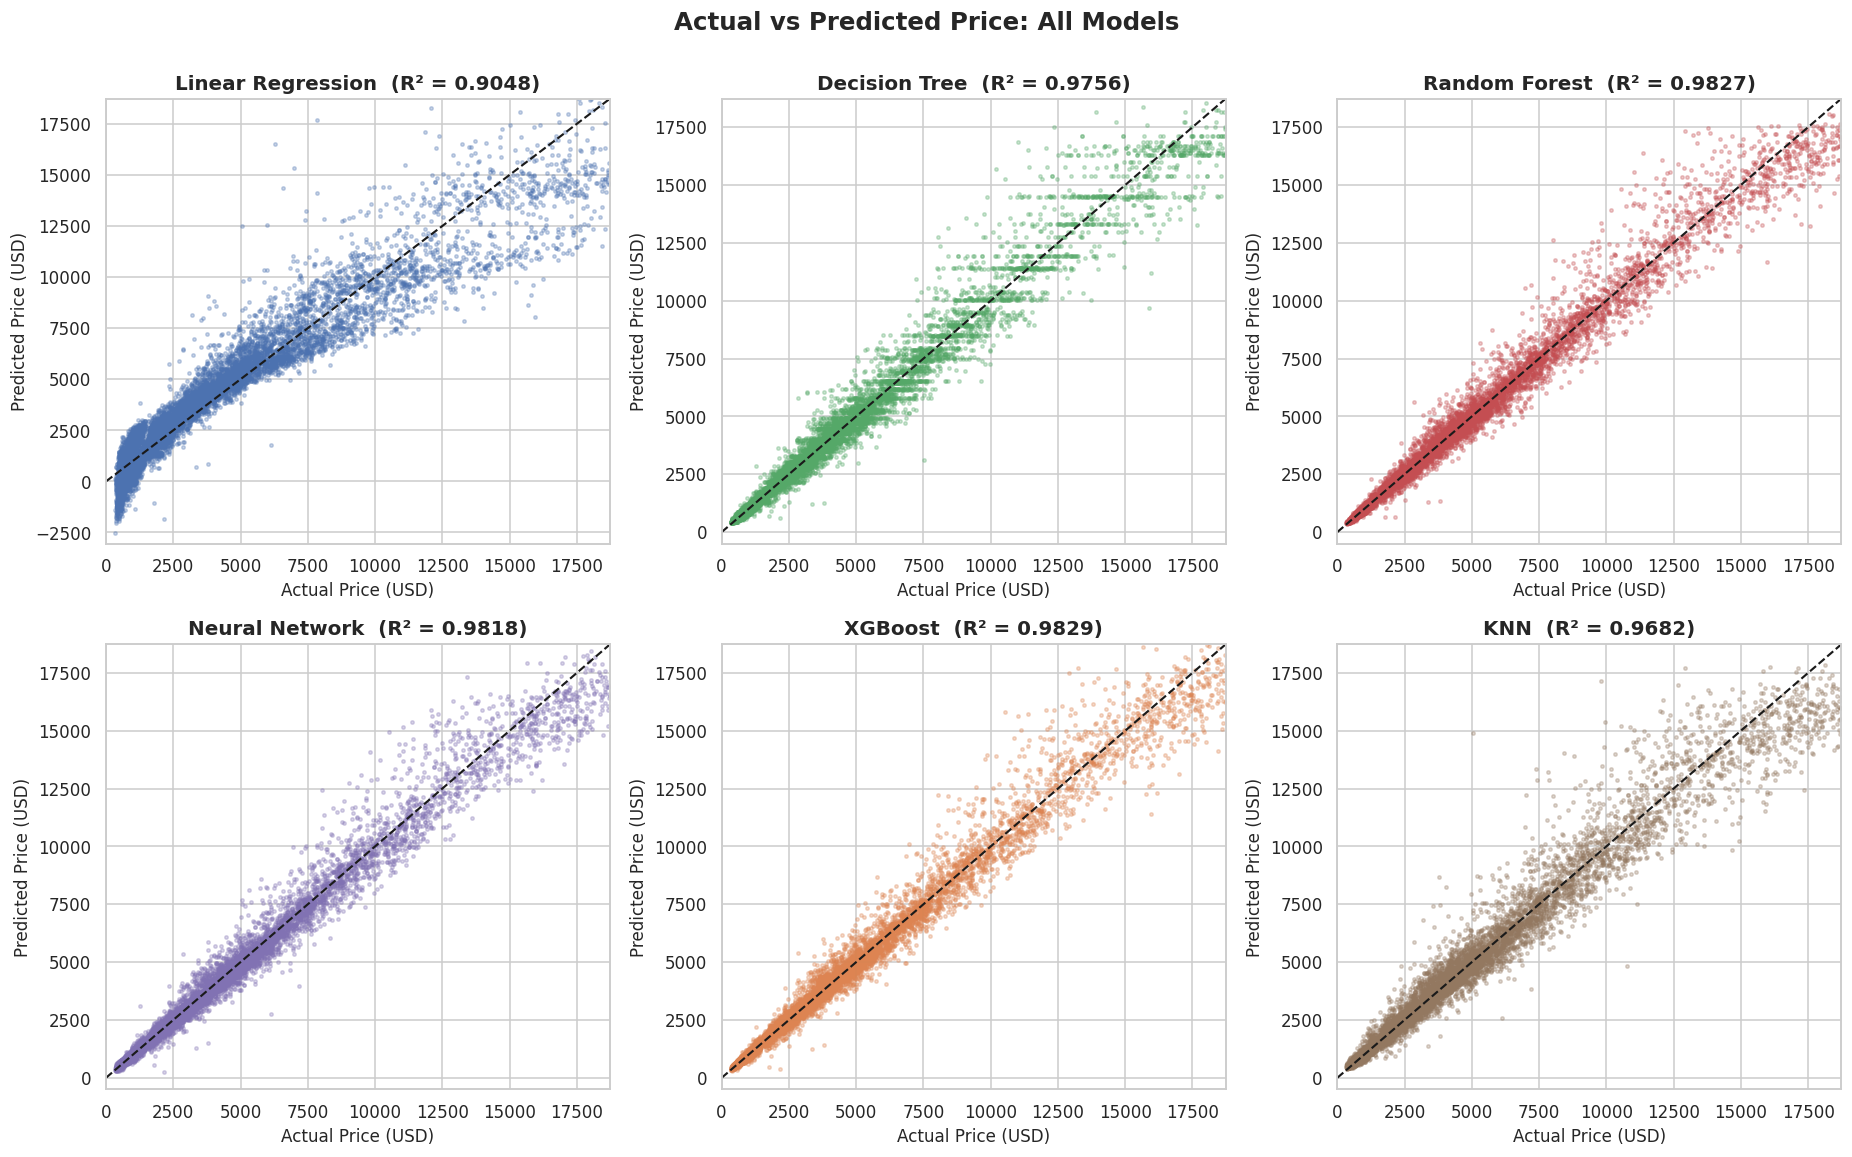

In [45]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10.5))
lim = [0, y_test.max()]
for ax, name in zip(axes.ravel(), order):
    pred = test_predictions[name]
    ax.scatter(y_test, pred, s=5, alpha=0.3, color=MODEL_COLORS[name])
    ax.plot(lim, lim, "k--", lw=1.4)
    ax.set_title(f"{name}  (R² = {res.loc[name, 'R2']:.4f})")
    ax.set_xlabel("Actual Price (USD)")
    ax.set_ylabel("Predicted Price (USD)")
    ax.set_xlim(lim)
    ax.set_ylim(min(0, pred.min()) - 500, lim[1])
fig.suptitle("Actual vs Predicted Price: All Models", fontsize=16, fontweight="bold", y=1.0)
fig.tight_layout()
save_fig(fig, "29_actual_vs_predicted_all")

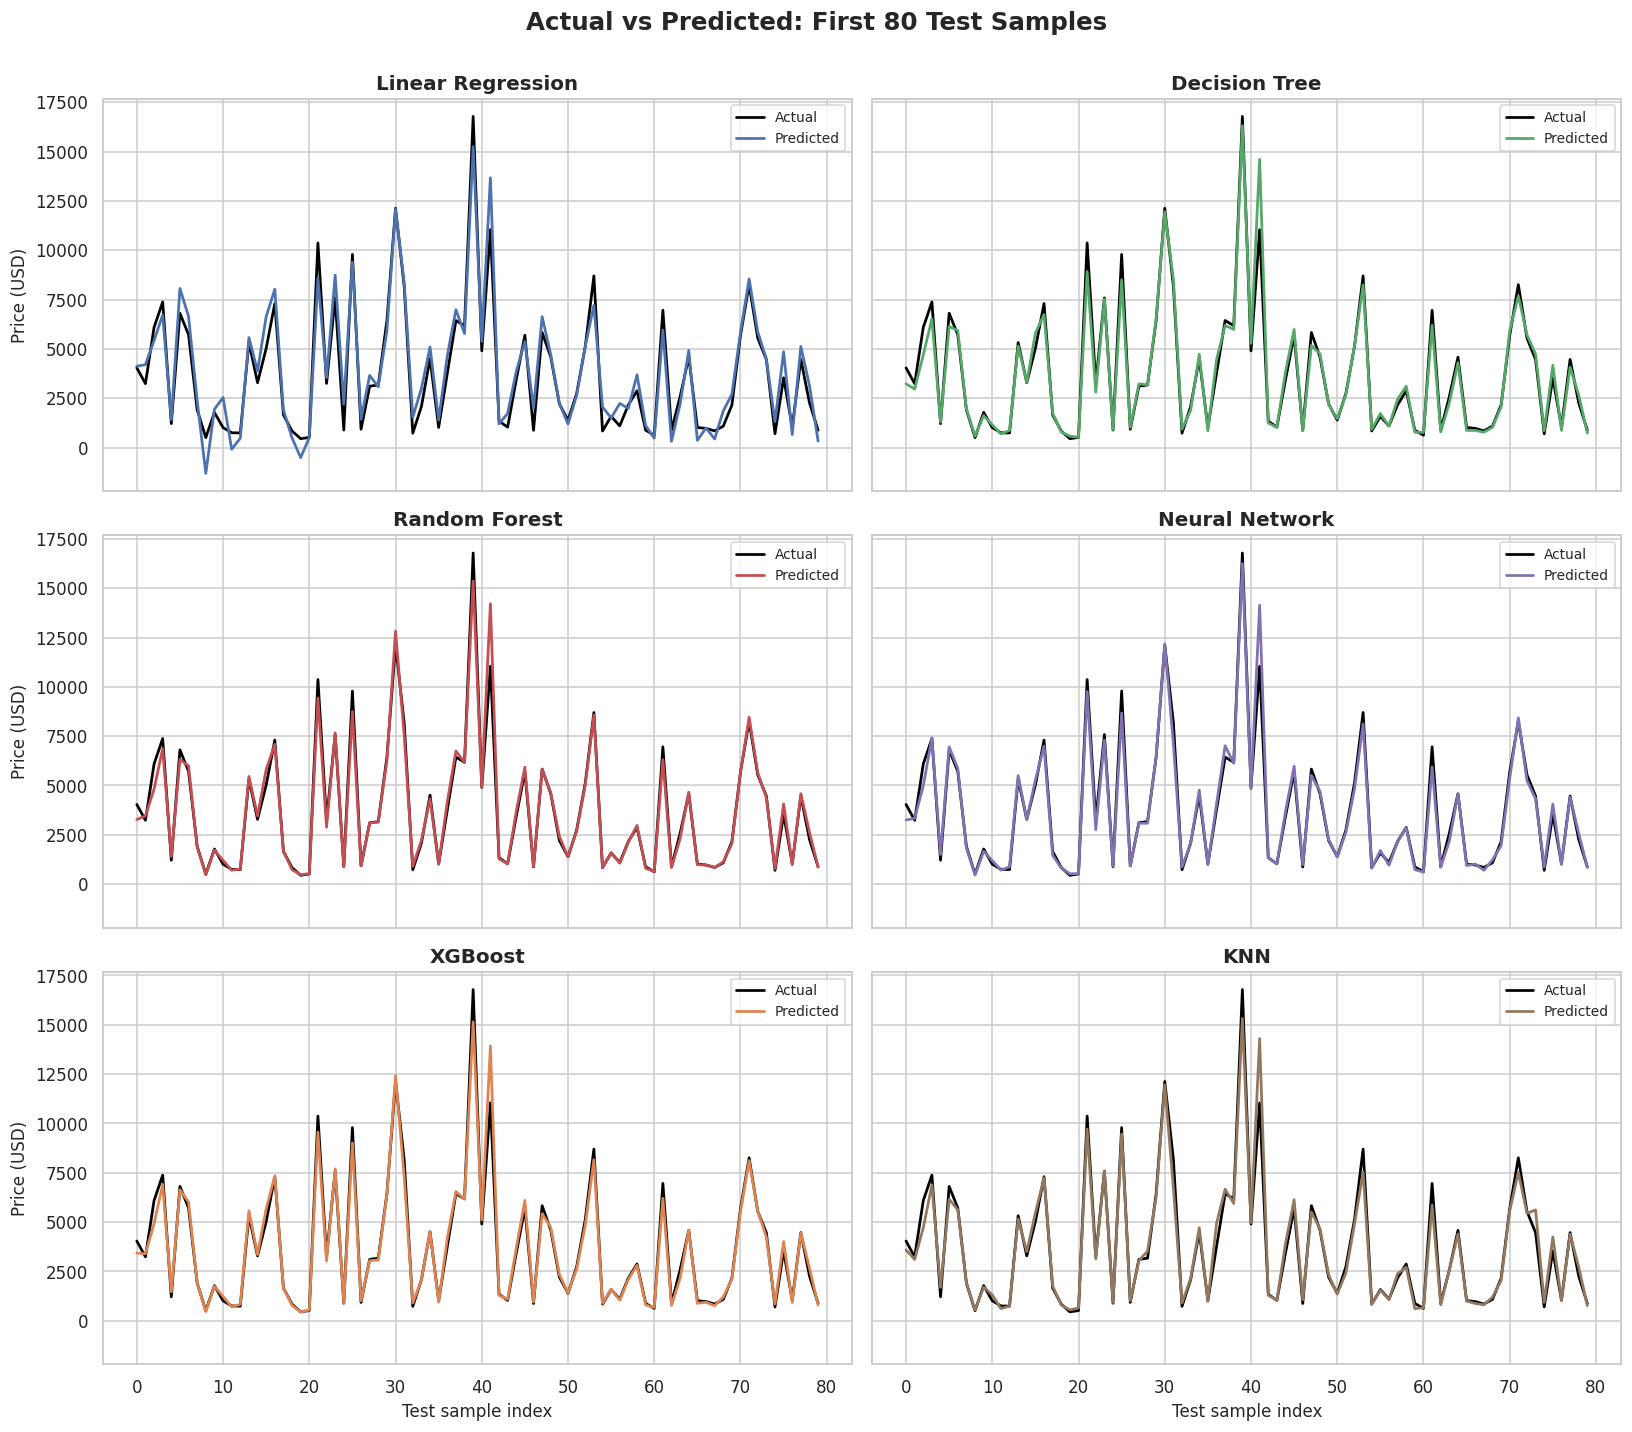

In [46]:
fig, axes = plt.subplots(3, 2, figsize=(15, 13), sharex=True, sharey=True)
n = 80
idx = np.arange(n)
for ax, name in zip(axes.ravel(), order):
    ax.plot(idx, y_test.values[:n], color="black", lw=1.8, label="Actual")
    ax.plot(idx, test_predictions[name][:n], color=MODEL_COLORS[name], lw=1.8, label="Predicted")
    ax.set_title(name)
    ax.legend(loc="upper right")
for ax in axes[-1]:
    ax.set_xlabel("Test sample index")
for ax in axes[:, 0]:
    ax.set_ylabel("Price (USD)")
fig.suptitle("Actual vs Predicted: First 80 Test Samples", fontsize=16, fontweight="bold", y=1.0)
fig.tight_layout()
save_fig(fig, "30_actual_vs_predicted_lines")

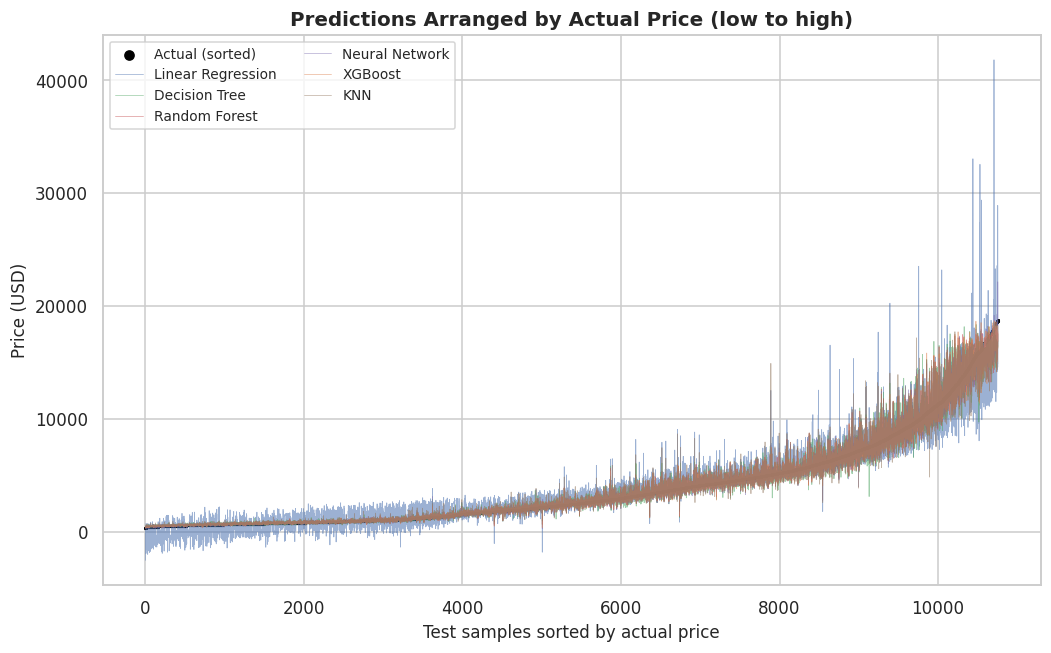

In [47]:
fig, ax = plt.subplots(figsize=(11, 6.5))
ax.scatter(range(len(y_test)), np.sort(y_test.values), s=1, color="black", label="Actual (sorted)")
sorted_idx = np.argsort(y_test.values)
for name in order:
    ax.plot(test_predictions[name][sorted_idx], lw=0.5, alpha=0.55, color=MODEL_COLORS[name], label=name)
ax.set_title("Predictions Arranged by Actual Price (low to high)")
ax.set_xlabel("Test samples sorted by actual price")
ax.set_ylabel("Price (USD)")
ax.legend(markerscale=6, ncol=2)
save_fig(fig, "31_sorted_predictions")

### 12.4 Error Analysis

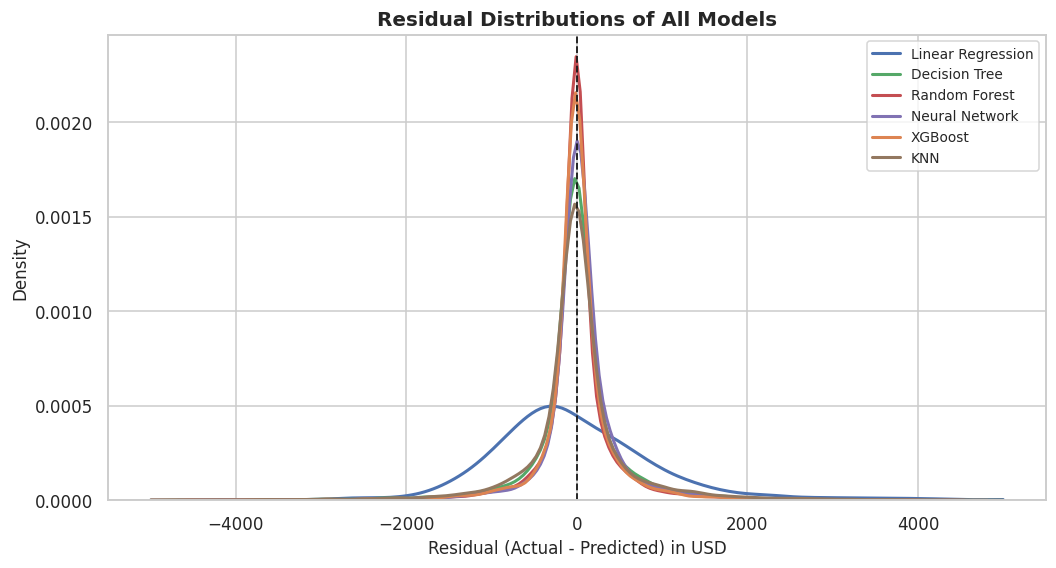

In [48]:
fig, ax = plt.subplots(figsize=(11, 5.5))
for name in order:
    resid = y_test.values - test_predictions[name]
    sns.kdeplot(resid, ax=ax, lw=2, color=MODEL_COLORS[name], label=name, clip=(-5000, 5000))
ax.axvline(0, color="k", ls="--", lw=1.2)
ax.set_title("Residual Distributions of All Models")
ax.set_xlabel("Residual (Actual - Predicted) in USD")
ax.legend()
save_fig(fig, "32_residual_kde")

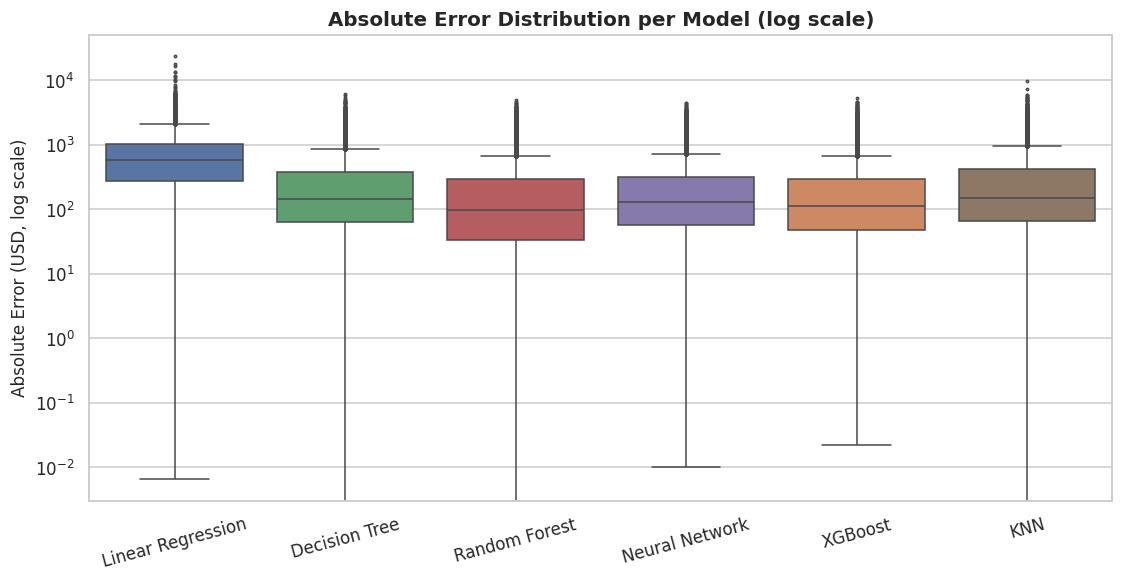

In [49]:
abs_err = pd.DataFrame({n: np.abs(y_test.values - test_predictions[n]) for n in order})
fig, ax = plt.subplots(figsize=(12, 5.5))
sns.boxplot(data=abs_err, palette=[MODEL_COLORS[n] for n in order], ax=ax, fliersize=1.5)
ax.set_yscale("log")
ax.set_title("Absolute Error Distribution per Model (log scale)")
ax.set_ylabel("Absolute Error (USD, log scale)")
ax.tick_params(axis="x", rotation=15)
save_fig(fig, "33_absolute_error_boxplot")

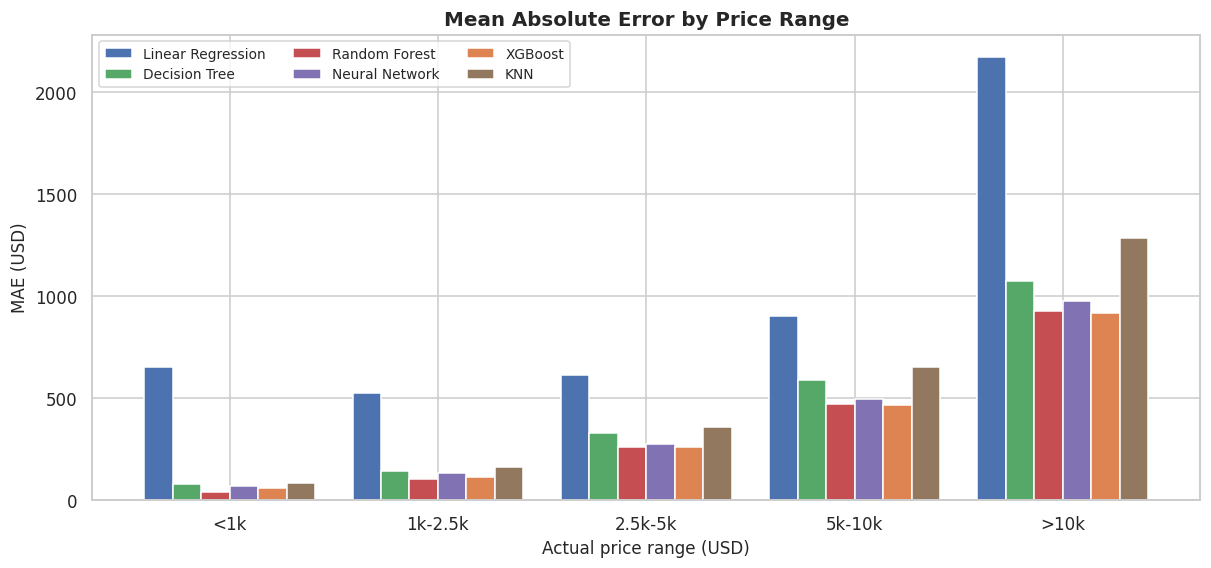

,Linear Regression,Decision Tree,Random Forest,Neural Network,XGBoost,KNN
<1k,652.0,79.9,40.7,70.6,60.2,82.8
1k-2.5k,525.9,142.2,103.9,133.5,113.3,164.0
2.5k-5k,613.0,330.7,262.3,274.6,262.6,360.0
5k-10k,904.9,591.7,473.4,495.8,466.2,651.8
>10k,2175.1,1077.7,929.2,978.5,918.6,1285.2


In [50]:
bins = [0, 1000, 2500, 5000, 10000, 20000]
labels = ["<1k", "1k-2.5k", "2.5k-5k", "5k-10k", ">10k"]
price_band = pd.cut(y_test.values, bins=bins, labels=labels)
band_mae = pd.DataFrame({n: pd.Series(np.abs(y_test.values - test_predictions[n])).groupby(price_band).mean() for n in order})

fig, ax = plt.subplots(figsize=(13, 5.5))
band_mae.plot(kind="bar", ax=ax, color=[MODEL_COLORS[n] for n in order], width=0.82, edgecolor="white")
ax.set_title("Mean Absolute Error by Price Range")
ax.set_xlabel("Actual price range (USD)")
ax.set_ylabel("MAE (USD)")
ax.tick_params(axis="x", rotation=0)
ax.legend(ncol=3)
save_fig(fig, "34_mae_by_price_range")
band_mae.round(1)

### 12.5 Overfitting Check and Training Time

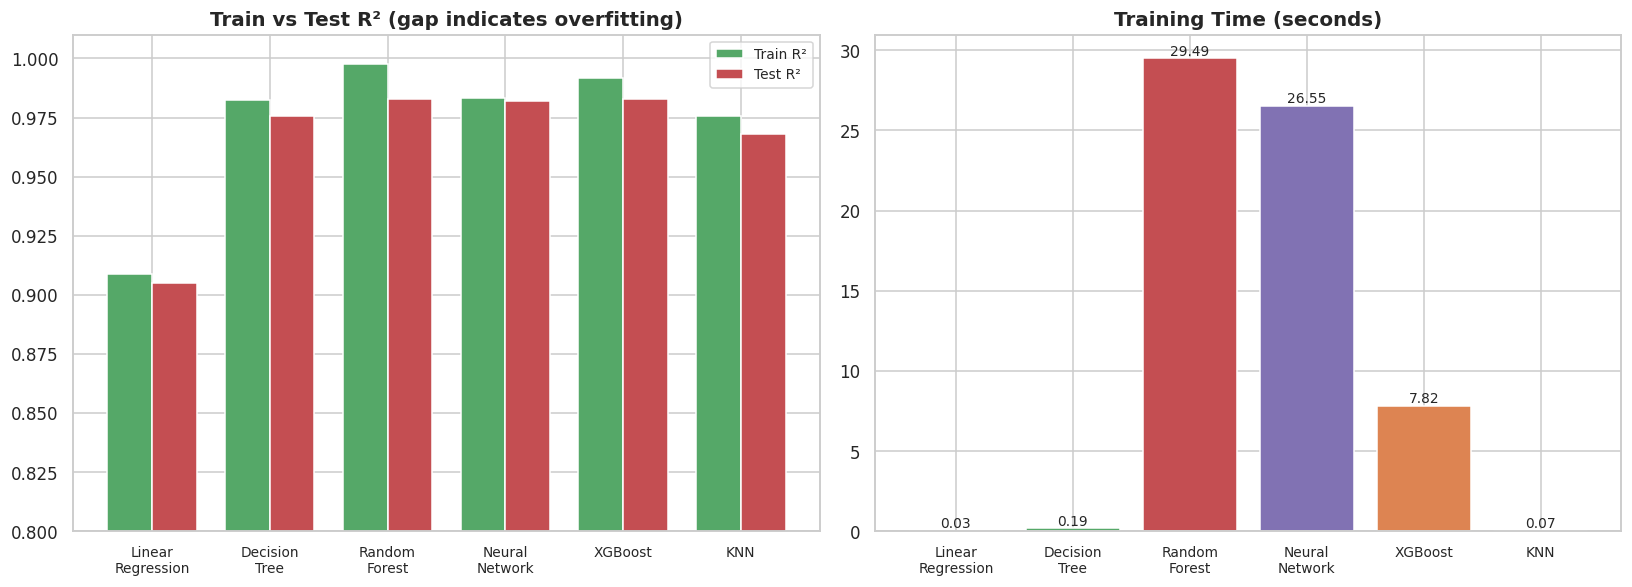

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
x = np.arange(len(order))
w = 0.38
axes[0].bar(x - w / 2, res["Train R2"], w, label="Train R²", color="#55A868")
axes[0].bar(x + w / 2, res["R2"], w, label="Test R²", color="#C44E52")
axes[0].set_xticks(x)
axes[0].set_xticklabels([n.replace(" ", "\n") for n in order], fontsize=9)
axes[0].set_ylim(0.8, 1.01)
axes[0].set_title("Train vs Test R² (gap indicates overfitting)")
axes[0].legend()

bars = axes[1].bar(x, res["Train Time (s)"], color=[MODEL_COLORS[n] for n in order])
axes[1].set_xticks(x)
axes[1].set_xticklabels([n.replace(" ", "\n") for n in order], fontsize=9)
axes[1].set_title("Training Time (seconds)")
for b, v in zip(bars, res["Train Time (s)"]):
    axes[1].text(b.get_x() + b.get_width() / 2, b.get_height(), f"{v:.2f}", ha="center", va="bottom", fontsize=9)
fig.tight_layout()
save_fig(fig, "35_overfitting_and_time")

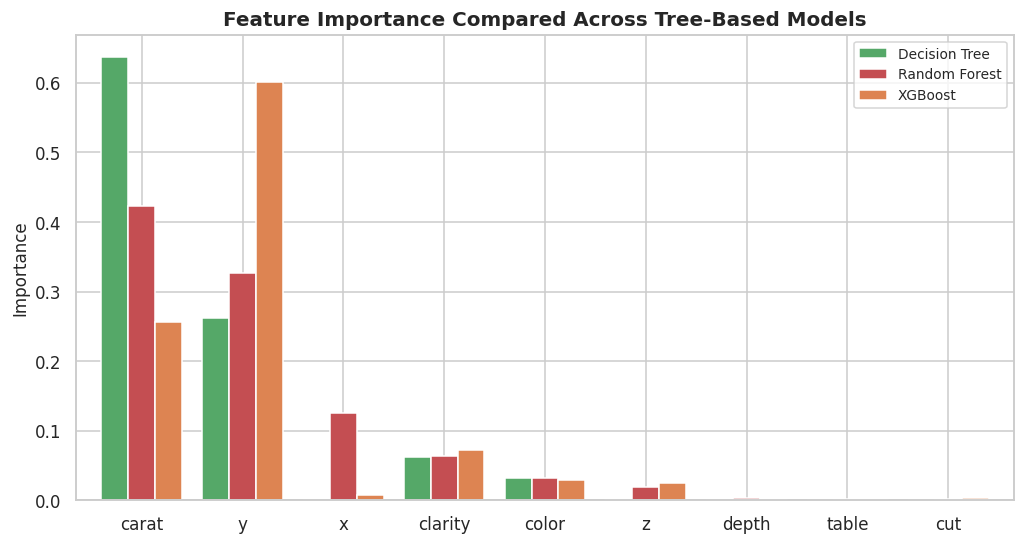

In [52]:
fi = pd.DataFrame({
    "Decision Tree": dt.feature_importances_,
    "Random Forest": rf.feature_importances_,
    "XGBoost": xgb.feature_importances_,
}, index=FEATURES)
fig, ax = plt.subplots(figsize=(11, 5.5))
fi.sort_values("Random Forest", ascending=False).plot(kind="bar", ax=ax, width=0.8,
        color=[MODEL_COLORS[c] for c in fi.columns], edgecolor="white")
ax.set_title("Feature Importance Compared Across Tree-Based Models")
ax.set_ylabel("Importance")
ax.tick_params(axis="x", rotation=0)
save_fig(fig, "36_feature_importance_comparison")

In [53]:
best_name = res["RMSE"].idxmin()
print("Best model by RMSE:", best_name)
print("Best model by R2  :", res["R2"].idxmax())
print("Best model by MAE :", res["MAE"].idxmin())
print()
print(res[["MAE", "RMSE", "R2"]].round(4))

Best model by RMSE: XGBoost
Best model by R2  : XGBoost
Best model by MAE : Random Forest

                        MAE       RMSE      R2
Model                                         
Linear Regression  797.9083  1215.8000  0.9048
Decision Tree      332.6282   615.9273  0.9756
Random Forest      263.0309   518.7971  0.9827
Neural Network     289.4426   531.8830  0.9818
XGBoost            268.3945   515.0551  0.9829
KNN                374.7222   702.7961  0.9682


## 13. Discussion: Strengths, Limitations and Final Conclusion

### 13.1 Summary of Results (test set, 80:20 split)

| Model | MAE | RMSE | R² |
|---|---|---|---|
| Linear Regression | 797.91 | 1,215.80 | 0.9048 |
| Decision Tree | 332.63 | 615.93 | 0.9756 |
| Random Forest | 263.03 | 518.80 | 0.9827 |
| Neural Network | 289.44 | 531.88 | 0.9818 |
| **XGBoost** | 268.39 | **515.06** | **0.9829** |
| KNN | 374.72 | 702.80 | 0.9682 |

Values come from one run with `random_state = 42`. Re-running on another machine may change the last decimals slightly, but the ranking of the models stays the same.

### 13.2 Strengths and Limitations of Each Algorithm

**Linear Regression**
- Strengths: extremely fast, easy to interpret (each coefficient shows the effect of a feature), no hyper-parameters, works as a good baseline.
- Limitations: assumes a straight-line relationship. Diamond price grows non-linearly with carat, so the model under-predicts expensive stones and even predicts negative prices for very cheap ones (visible in the actual vs predicted plot). Sensitive to correlated features (x, y, z, carat) and outliers.

**Decision Tree**
- Strengths: captures non-linear relationships and feature interactions automatically, needs no scaling, easy to visualise and explain.
- Limitations: a single tree is unstable and prone to overfitting (train R² is higher than test R²). Predictions are piece-wise constant, which produces the horizontal bands seen in its scatter plot.

**Random Forest**
- Strengths: averaging many trees removes most of the variance of a single tree, very robust, handles non-linearity and mixed feature types, gives feature importance, little tuning needed.
- Limitations: largest gap between train R² and test R² among the models, slower to train and predict, uses more memory, less interpretable than one tree, cannot extrapolate beyond the price range seen in training.

**Neural Network**
- Strengths: learns smooth, complex non-linear functions, gives very good accuracy, produces smooth predictions without the banding of trees.
- Limitations: requires scaling of inputs and target, many hyper-parameters (layers, neurons, learning rate), slower training, results vary with the random seed, and the model is hard to interpret.

**XGBoost**
- Strengths: sequentially corrects errors, built-in regularisation (λ, γ, subsampling), fast training for its accuracy, handles non-linearity and interactions, gives feature importance. Best RMSE and R² in this experiment.
- Limitations: more hyper-parameters to tune (learning rate, depth, number of rounds), can overfit if too many rounds are used, less interpretable than a single tree.

**K-Nearest Neighbors**
- Strengths: simple idea, no training phase, naturally non-linear.
- Limitations: needs scaled features, prediction is slow on large data because every query is compared with all training points, performance drops when features are irrelevant or correlated, and it is sensitive to the choice of K.

### 13.3 Observations from the Experiment

- All non-linear models clearly outperform Linear Regression (R² ≈ 0.97 to 0.98 versus 0.90), which confirms that the relationship between the features and price is non-linear.
- The three best models (XGBoost, Random Forest, Neural Network) are very close to each other. The difference between them is small compared with their gap from Linear Regression.
- Errors of every model grow with the price. Expensive diamonds are rare, so there are fewer examples to learn from (see the MAE by price range chart).
- `carat` and the physical size (x, y, z) are the most important features, followed by `clarity` and `color` (see the feature importance charts).

### 13.4 Best Performing Algorithm

**XGBoost Regression is the best model in this experiment.** It achieved the lowest RMSE (≈ 515 USD) and the highest R² (≈ 0.983), meaning it explains about 98.3% of the variance in diamond prices.

Justification:
1. It has the best RMSE, MSE and R². RMSE penalises large errors, which matter most for expensive diamonds.
2. Random Forest has a slightly lower MAE, but its RMSE and R² are lower, so it makes a few larger mistakes than XGBoost.
3. XGBoost trains about 6 times faster than Random Forest here and its train-test R² gap is smaller than that of Random Forest, so it generalises better for the same level of accuracy.
4. The Neural Network is almost as accurate, but it needs scaling, careful tuning and has no direct feature importance.

The difference between XGBoost, Random Forest and the Neural Network is small, so the three can be treated as practically equivalent in accuracy. XGBoost is selected because it gives the best balance of accuracy, speed and generalisation.

## 14. Appendix: Verification of the Handwritten Sample (NumPy)

The handwritten solutions use a tiny sample of 5 training diamonds and 2 test diamonds (price in thousands of USD). The cells below recompute every handwritten step with NumPy so the hand calculations can be checked.

In [54]:
X_h = np.array([0.3, 0.5, 0.7, 0.9, 1.2])
D_h = np.array([62.0, 61.6, 61.6, 62.7, 62.8])
y_h = np.array([0.6, 1.4, 2.8, 4.1, 7.2])
Xt_h = np.array([0.8, 1.0])
Dt_h = np.array([62.2, 62.3])
yt_h = np.array([2.8, 5.8])

def metrics_h(y_true, y_pred):
    e = y_true - y_pred
    mae, mse = np.abs(e).mean(), (e ** 2).mean()
    r2 = 1 - (e ** 2).sum() / ((y_true - y_true.mean()) ** 2).sum()
    return pd.Series({"MAE": mae, "MSE": mse, "RMSE": np.sqrt(mse), "R2": r2})

hand_results = {}

sample_df = pd.DataFrame({"carat": np.r_[X_h, Xt_h], "depth": np.r_[D_h, Dt_h], "price (k$)": np.r_[y_h, yt_h]},
                         index=["Train 1", "Train 2", "Train 3", "Train 4", "Train 5", "Test 1", "Test 2"])
sample_df

,carat,depth,price (k$)
Train 1,0.3,62.0,0.6
Train 2,0.5,61.6,1.4
Train 3,0.7,61.6,2.8
Train 4,0.9,62.7,4.1
Train 5,1.2,62.8,7.2
Test 1,0.8,62.2,2.8
Test 2,1.0,62.3,5.8


In [55]:
x_bar, y_bar = X_h.mean(), y_h.mean()
b1 = ((X_h - x_bar) * (y_h - y_bar)).sum() / ((X_h - x_bar) ** 2).sum()
b0 = y_bar - b1 * x_bar
pred_lr = b0 + b1 * Xt_h
print(f"x_bar = {x_bar:.4f}, y_bar = {y_bar:.4f}")
print(f"beta1 = {b1:.4f}, beta0 = {b0:.4f}")
print("Predictions:", pred_lr.round(4))
hand_results["Linear Regression"] = metrics_h(yt_h, pred_lr)

x_bar = 0.7200, y_bar = 3.2200
beta1 = 7.3320, beta0 = -2.0590
Predictions: [3.8066 5.273 ]


In [56]:
dt_h = DecisionTreeRegressor(max_depth=2, random_state=0).fit(X_h.reshape(-1, 1), y_h)
pred_dt = dt_h.predict(Xt_h.reshape(-1, 1))
print("Tree thresholds:", dt_h.tree_.threshold[dt_h.tree_.threshold != -2].round(3))
print("Predictions:", pred_dt)
hand_results["Decision Tree"] = metrics_h(yt_h, pred_dt)

Tree thresholds: [1.05 0.6 ]
Predictions: [3.45 3.45]


In [57]:
def best_stump(xv, yv):
    xs = np.unique(xv)
    best = None
    for t in (xs[:-1] + xs[1:]) / 2:
        l, r = yv[xv <= t], yv[xv > t]
        s = ((l - l.mean()) ** 2).sum() + ((r - r.mean()) ** 2).sum()
        if best is None or s < best[0]:
            best = (s, t, l.mean(), r.mean())
    return best

boots = [[0, 1, 1, 3, 4], [1, 2, 3, 3, 4], [0, 2, 2, 4, 4]]
tree_preds = []
for i, b in enumerate(boots, 1):
    s, t, lm, rm = best_stump(X_h[b], y_h[b])
    print(f"Tree {i}: bootstrap rows {[j + 1 for j in b]}, split at carat <= {t:.2f}, leaf means {lm:.4f} / {rm:.4f}")
    tree_preds.append(np.where(Xt_h <= t, lm, rm))
pred_rf = np.mean(tree_preds, axis=0)
print("Averaged predictions:", pred_rf.round(4))
hand_results["Random Forest"] = metrics_h(yt_h, pred_rf)

Tree 1: bootstrap rows [1, 2, 2, 4, 5], split at carat <= 0.70, leaf means 1.1333 / 5.6500
Tree 2: bootstrap rows [2, 3, 4, 4, 5], split at carat <= 1.05, leaf means 3.1000 / 7.2000
Tree 3: bootstrap rows [1, 3, 3, 5, 5], split at carat <= 0.95, leaf means 2.0667 / 7.2000
Averaged predictions: [3.6056 5.3167]


In [58]:
W1 = np.array([0.8, 0.6]); b1v = np.array([0.1, -0.1]); W2 = np.array([0.7, 0.5]); b2 = 0.2
xs = (X_h - X_h.min()) / (X_h.max() - X_h.min())
xts = (Xt_h - X_h.min()) / (X_h.max() - X_h.min())

def forward(x, W1, b1v, W2, b2):
    z = W1 * x + b1v
    h = np.maximum(0, z)
    return z, h, W2 @ h + b2

before = np.array([forward(x, W1, b1v, W2, b2)[2] for x in xs])
print("Initial predictions:", before.round(4), "| MSE:", round(((before - y_h) ** 2).mean(), 4))

x_i, y_i = xs[4], y_h[4]
z, h, o = forward(x_i, W1, b1v, W2, b2)
err = o - y_i
dW2, db2 = err * h, err
dz = err * W2 * (z > 0)
dW1, db1 = dz * x_i, dz
lr_h = 0.05
W2n, b2n, W1n, b1n = W2 - lr_h * dW2, b2 - lr_h * db2, W1 - lr_h * dW1, b1v - lr_h * db1
print("Sample 5 error before update:", round(err, 4))
print("dW2:", dW2.round(4), "db2:", round(db2, 4), "dW1:", dW1.round(4), "db1:", db1.round(4))
print("Updated W1:", W1n.round(4), "b1:", b1n.round(4), "W2:", W2n.round(4), "b2:", round(b2n, 4))
print("Sample 5 prediction after update:", round(forward(x_i, W1n, b1n, W2n, b2n)[2], 4))

test_h = [forward(x, W1n, b1n, W2n, b2n)[2] for x in xts]
print("NN test predictions after one update:", np.round(test_h, 4))
hand_results["Neural Network"] = metrics_h(yt_h, np.array(test_h))

Initial predictions: [0.27   0.4111 0.6022 0.7933 1.08  ] | MSE: 10.8611
Sample 5 error before update: -6.12
dW2: [-5.508 -3.06 ] db2: -6.12 dW1: [-4.284 -3.06 ] db1: [-4.284 -3.06 ]
Updated W1: [1.0142 0.753 ] b1: [0.3142 0.053 ] W2: [0.9754 0.653 ] b2: 0.506
Sample 5 prediction after update: 2.328
NN test predictions after one update: [1.6698 1.9989]


In [59]:
lam, eta = 1.0, 0.5
pred_tr = np.full(5, y_h.mean())
pred_te = np.full(2, y_h.mean())
for rnd in (1, 2):
    g = pred_tr - y_h
    G, H = g.sum(), 5
    best = None
    for t in [0.4, 0.6, 0.8, 1.05]:
        L = X_h <= t
        GL, HL = g[L].sum(), L.sum()
        GR, HR = G - GL, H - HL
        gain = 0.5 * (GL ** 2 / (HL + lam) + GR ** 2 / (HR + lam) - G ** 2 / (H + lam))
        if best is None or gain > best[0]:
            best = (gain, t, -GL / (HL + lam), -GR / (HR + lam))
    gain, t, wl, wr = best
    print(f"Round {rnd}: best split carat <= {t}, gain = {gain:.4f}, w_left = {wl:.4f}, w_right = {wr:.4f}")
    pred_tr = pred_tr + eta * np.where(X_h <= t, wl, wr)
    pred_te = pred_te + eta * np.where(Xt_h <= t, wl, wr)
    print("  train predictions:", pred_tr.round(4))
print("Test predictions:", pred_te.round(4))
hand_results["XGBoost"] = metrics_h(yt_h, pred_te)

Round 1: best split carat <= 0.8, gain = 6.8890, w_left = -1.2150, w_right = 1.6200
  train predictions: [2.6125 2.6125 2.6125 4.03   4.03  ]
Round 2: best split carat <= 1.05, gain = 3.3894, w_left = -0.5935, w_right = 1.5850
  train predictions: [2.3158 2.3158 2.3158 3.7332 4.8225]
Test predictions: [2.3158 3.7332]


In [60]:
mn = np.array([X_h.min(), D_h.min()])
mx = np.array([X_h.max(), D_h.max()])
A = (np.c_[X_h, D_h] - mn) / (mx - mn)
B = (np.c_[Xt_h, Dt_h] - mn) / (mx - mn)
pred_knn = []
for q in B:
    d = np.sqrt(((A - q) ** 2).sum(axis=1))
    nn_idx = np.argsort(d)[:3]
    print("distances:", d.round(4), "| 3 nearest (train #):", nn_idx + 1, "| prices:", y_h[nn_idx])
    pred_knn.append(y_h[nn_idx].mean())
pred_knn = np.array(pred_knn)
print("Predictions:", pred_knn.round(4))
hand_results["KNN"] = metrics_h(yt_h, pred_knn)

distances: [0.58   0.6009 0.5122 0.4312 0.669 ] | 3 nearest (train #): [4 3 1] | prices: [4.1 2.8 0.6]
distances: [0.817  0.8056 0.6719 0.3514 0.4722] | 3 nearest (train #): [4 5 3] | prices: [4.1 7.2 2.8]
Predictions: [2.5 4.7]


In [61]:
pd.DataFrame(hand_results).T.loc[["Linear Regression", "Decision Tree", "Random Forest", "Neural Network", "XGBoost", "KNN"]].round(4)

,MAE,MSE,RMSE,R2
Linear Regression,0.7668,0.6455,0.8034,0.7131
Decision Tree,1.5000,2.9725,1.7241,-0.3211
Random Forest,0.6444,0.4413,0.6643,0.8039
Neural Network,2.4656,7.8627,2.8040,-2.4945
XGBoost,1.2755,2.2530,1.5010,-0.0013
KNN,0.7000,0.6500,0.8062,0.7111


In [62]:
!zip -r assets.zip assets

  adding: assets/ (stored 0%)
  adding: assets/36_feature_importance_comparison.png (deflated 22%)
  adding: assets/26_comparison_table.png (deflated 14%)
  adding: assets/33_absolute_error_boxplot.png (deflated 18%)
  adding: assets/20_nn_diagnostics.png (deflated 6%)
  adding: assets/12_dt_tree_structure.png (deflated 9%)
  adding: assets/29_actual_vs_predicted_all.png (deflated 4%)
  adding: assets/18_nn_learning_curves.png (deflated 12%)
  adding: assets/17_rf_diagnostics.png (deflated 5%)
  adding: assets/23_xgb_diagnostics.png (deflated 6%)
  adding: assets/16_rf_feature_importance.png (deflated 27%)
  adding: assets/02_numeric_feature_distributions.png (deflated 14%)
  adding: assets/27_metric_comparison.png (deflated 22%)
  adding: assets/03_categorical_counts.png (deflated 22%)
  adding: assets/24_knn_k_curve.png (deflated 15%)
  adding: assets/07_correlation_heatmap.png (deflated 10%)
  adding: assets/34_mae_by_price_range.png (deflated 22%)
  adding: assets/28_rank_heatmap.p